# AI-Based Personalized Handwriting Generator
### VATr (Pippi et al., *Handwritten Text Generation from Visual Archetypes*, CVPR 2023) with a **ResNet-50** style encoder

**Goal:** give the model a piece of **text** + a **handwriting style** (15 word images from a writer, or a photo of your own handwriting) → it writes the text in that style.

**Architecture (follows the paper, Fig. 2):**

| Block | Paper | This notebook |
|---|---|---|
| Style CNN backbone | ResNet-18, pre-trained on synthetic calligraphic fonts | **ResNet-50** (ImageNet weights, grayscale stem) + pre-training on IAM writer classification (the paper's "IAM pre-training" row in Table 1) |
| Style Transformer encoder | 3 layers, 8 heads, d = 512 | same |
| Content queries | **Visual archetypes**: GNU Unifont 16×16 glyphs → flatten → Linear(256 → 512) | same |
| Transformer decoder | 3 layers, 8 heads, cross-attention to style vectors | same |
| Image decoder | + Gaussian noise → Linear(512 → 8192) → reshape 512×4×4k → 4 residual blocks → tanh | same (output: 32 px high, 16 px per character) |
| Losses | L = L_adv (hinge) + L_HTR (CTC) + L_class (writer CE) + L_cycle (‖E(X) − E(Y)‖₁) | same, equal weights |
| Optimiser | Adam, lr 2·10⁻⁴, batch 8 | same |

**Pipeline:** ① parse & cache IAM → ② build visual archetypes → ③ Stage 1: pre-train the ResNet-50 style backbone + HTR + writer classifier on real data → ④ Stage 2: adversarial VATr training (time-budgeted, auto-checkpointing, resumable, **validation every few thousand steps → the best model is kept as `best_G.pt`**) → ⑤ **full evaluation of the best model**: CER, WER, word accuracy, character precision/recall/F1 + confusion matrix, **FID, KID, GS (Geometry Score)**, writer-identification accuracy / precision / recall / F1 / Cohen κ / MCC / top-5 + confusion matrices, unseen-writer style retrieval → ⑥ generate any text in any style (IAM writer or **your own handwriting photo**) → ⑦ export.

One "Save & Run All" run does **everything** (training stops automatically early enough to leave time for evaluation, generation and export inside Kaggle's 12-hour limit).

---
### How to run on Kaggle
1. **Upload the dataset**: zip your `dataset` folder (the one containing `ascii/`, `words/`, …) → Kaggle → *Datasets → New Dataset* → upload. Any folder name is fine; the notebook finds `words.txt`, `forms.txt` and the word PNGs automatically.
2. **New notebook** → *Add Input* → your IAM dataset.
3. *Settings*: **Accelerator = GPU P100 or GPU T4** (one GPU is used), **Internet = On** (to download ImageNet weights and GNU Unifont; there are fallbacks if it's off).
4. For the long training run use **Save Version → Save & Run All (Commit)**: it runs in the background for up to 12 h, even with your browser closed, and keeps everything in `/kaggle/working` as the notebook's output.
5. **Continue training in a new session**: *Add Input → Notebook Output* (pick your previous version). The notebook automatically finds `checkpoints/last.pt` and resumes. You can also set `CFG.resume_path` by hand.
6. **Quick test first**: set `CFG.DEBUG = True` and run all (~5 min) to check that everything works, then set it back to `False`.

## 0. Imports & configuration

In [1]:
import os, sys, glob, re, math, time, json, gzip, random, pickle, string, copy, io, urllib.request
from collections import defaultdict, Counter
from multiprocessing import Pool

import numpy as np
import cv2
from PIL import Image, ImageDraw, ImageFont
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torch.func import functional_call

NB_START = time.time()          # used for the Kaggle time budget
print('torch', torch.__version__, '| torchvision', torchvision.__version__)
print('CUDA:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

torch 2.11.0+cu130 | torchvision 0.26.0+cu130
CUDA: True Tesla T4


In [2]:
class CFG:
    # ---------------- paths ----------------
    input_root   = os.environ.get('IAM_INPUT_ROOT', '/kaggle/input')   # where Kaggle mounts datasets
    work_dir     = os.environ.get('VATR_WORK_DIR', '/kaggle/working')   # everything we write goes here
    resume_path  = None      # e.g. '/kaggle/input/my-prev-run/checkpoints/last.pt'  (None = auto-detect)
    kaggle_dataset = 'venkatanarayana55/dataset-dl'   # used only if the dataset is NOT attached as an input

    # ---------------- data ----------------
    img_h        = 32        # word images are resized to 32 px height (16 px per generated char)
    char_w       = 16
    style_w      = 128       # each style sample is squeezed / padded to 32 x 128
    num_style    = 15        # P = 15 style images per writer (paper)
    max_word_len = 12        # training words longer than this are skipped
    max_real_w   = 384       # cap on real image width after resize
    only_ok      = True      # use only words with segmentation status 'ok'
    min_words_per_writer = 20
    test_writer_frac = 0.32  # ~ 160 / 500 writers held out as unseen styles (paper: 340 train / 160 test)
    val_frac     = 0.05      # words of training writers held out for sanity checks

    # ---------------- model ----------------
    d_model      = 512
    n_heads      = 8
    enc_layers   = 3
    dec_layers   = 3
    ff_dim       = 1024
    dropout      = 0.1
    noise_std    = 0.2       # paper adds N(0,1) noise to F; 1.0 drowned the content signal in run 1 -> 0.2
    imagenet_pretrained = os.environ.get('VATR_PRETRAINED', '1') == '1'

    # ---------------- stage 1: pre-training on real images ----------------
    pretrain_epochs = 3
    pretrain_bs     = 64
    lr_backbone_pre = 1e-4

    # ---------------- stage 2: VATr adversarial training ----------------
    batch_size   = 8         # writers per batch (paper: 8)
    n_real       = 2         # real words per writer fed to D / R / W
    n_fake       = 4         # generated words per writer
    lr_g         = 2e-4      # paper: 2e-4
    lr_backbone  = 2e-5      # smaller lr for the pre-trained ResNet-50
    lr_d         = 1e-4      # D overpowered G in run 1 (D loss -> 0) -> half the generator lr
    content_warmup_steps = 5000   # first train G with HTR + writer + cycle losses only (no adversarial) -> learns legible content
    grad_balance = True      # HWT/VATr-style: scale HTR & writer gradients to the std of the adversarial gradient
    real_char_aligned = True # real words for D / R / W resized to 16 px per character, exactly like generated words
    freeze_backbone = True   # run 2: the style encoder collapsed -> keep the writer-pre-trained ResNet-50 fixed in stage 2
    w_style_enc  = 1.0       # writer-classification loss on the style vectors S (keeps the style encoder writer-aware)
    style_val_n  = 600       # seen-writer words used to measure style accuracy in every validation
    lr_aux       = 1e-4      # HTR recognizer + writer classifier
    w_adv, w_htr, w_cls, w_cyc = 1.0, 1.0, 1.0, 1.0   # equal weights (paper)
    grad_clip    = 10.0
    use_ema      = True
    ema_decay    = 0.999
    max_steps    = 500_000
    time_budget_hours = 11.0  # Kaggle kills GPU sessions at 12 h -> stop & save before that
    ckpt_every_min = 30
    log_every    = 200
    sample_every = 2000

    # ---------------- evaluation & best-model selection ----------------
    eval_every   = 4000      # quick validation on unseen writers (FID + CER) -> best model saved as best_G.pt
    quick_val_n  = 1000      # samples used by the quick validation
    final_eval_n = 5000      # samples per split (unseen / seen writers) in the final evaluation
    gs_n, gs_runs = 1000, 100   # Geometry Score: samples per set, number of witness-complex runs
    final_eval_reserve_h = 0.75 # training stops this long before the time budget ends -> evaluation + generation finish

    num_workers  = int(os.environ.get('VATR_WORKERS', 4))
    seed         = 42
    DEBUG        = os.environ.get('VATR_DEBUG', '0') == '1'   # set True for a 5-minute smoke test

CKPT_VERSION = 'v6-style'   # checkpoints from older notebook versions are ignored (they were collapsed)

if CFG.DEBUG:
    CFG.pretrain_epochs = 1; CFG.max_steps = 60; CFG.log_every = 10; CFG.sample_every = 30
    CFG.ckpt_every_min = 1; CFG.time_budget_hours = 0.5
    CFG.eval_every = 30; CFG.quick_val_n = 64; CFG.final_eval_n = 150; CFG.gs_n = 120; CFG.gs_runs = 5
    CFG.final_eval_reserve_h = 0.05; CFG.content_warmup_steps = 15; CFG.style_val_n = 48

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG.seed)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CKPT_DIR   = os.path.join(CFG.work_dir, 'checkpoints')
SAMPLE_DIR = os.path.join(CFG.work_dir, 'samples')
CACHE_DIR  = os.path.join(CFG.work_dir, 'cache')
EVAL_DIR   = os.path.join(CFG.work_dir, 'evaluation')
BEST_PATH  = os.path.join(CKPT_DIR, 'best_G.pt')
for d in (CKPT_DIR, SAMPLE_DIR, CACHE_DIR, EVAL_DIR): os.makedirs(d, exist_ok=True)

def time_left_h():
    return CFG.time_budget_hours - (time.time() - NB_START) / 3600
print('device:', DEVICE, '| DEBUG:', CFG.DEBUG)

device: cuda | DEBUG: False


## 1. Locate & parse the IAM dataset
`words.txt` line format: `a01-000u-00-00 ok 154 408 768 27 51 AT A` → id, segmentation status, …, transcription.
`forms.txt` maps each form (`a01-000u`) to its **writer id** — this is the "style" label.

In [3]:
SKIP_DIRS = {'lines', 'sentences', 'xml', 'forms', 'formsA-D', 'formsE-H', 'formsI-Z'}

def scan_iam(root):
    # One walk over the input folder: finds words.txt, forms.txt and indexes every word PNG by id.
    words_txt = forms_txt = None
    img_index = {}
    for dp, dns, fns in os.walk(root):
        dns[:] = [d for d in dns if d not in SKIP_DIRS and not d.startswith('.')]
        for fn in fns:
            if fn == 'words.txt' and words_txt is None: words_txt = os.path.join(dp, fn)
            elif fn == 'forms.txt' and forms_txt is None: forms_txt = os.path.join(dp, fn)
            elif fn.endswith('.png') and fn.count('-') == 3:
                img_index[fn[:-4]] = os.path.join(dp, fn)
    return words_txt, forms_txt, img_index

t0 = time.time()
WORDS_TXT, FORMS_TXT, IMG_INDEX = scan_iam(CFG.input_root)
if not (WORDS_TXT and FORMS_TXT and IMG_INDEX):
    # dataset not attached as input -> download it with kagglehub (needs Internet ON)
    print('IAM not found under', CFG.input_root, '-> downloading', CFG.kaggle_dataset, 'with kagglehub ...')
    try:
        import kagglehub
        dl_path = kagglehub.dataset_download(CFG.kaggle_dataset)
        print('downloaded to', dl_path)
        WORDS_TXT, FORMS_TXT, IMG_INDEX = scan_iam(dl_path)
    except Exception as e:
        print('kagglehub download failed:', repr(e))
print(f'scan took {time.time()-t0:.1f}s')
print('words.txt :', WORDS_TXT); print('forms.txt :', FORMS_TXT); print('word PNGs :', len(IMG_INDEX))
assert WORDS_TXT and FORMS_TXT and len(IMG_INDEX) > 0, ('IAM files not found. Click "+ Add Input" (right panel) and add your dataset '
        f'{CFG.kaggle_dataset}, or turn Internet on so it can be downloaded.')

def parse_forms(path):
    form2writer = {}
    for line in open(path, encoding='utf-8', errors='ignore'):
        if line.startswith('#') or not line.strip(): continue
        p = line.split()
        form2writer[p[0]] = p[1]
    return form2writer

def parse_words(path, only_ok=True):
    out = []
    for line in open(path, encoding='utf-8', errors='ignore'):
        if line.startswith('#') or not line.strip(): continue
        p = line.strip().split(' ')
        if len(p) < 9: continue
        if only_ok and p[1] != 'ok': continue
        out.append((p[0], ' '.join(p[8:])))
    return out

FORM2WRITER = parse_forms(FORMS_TXT)
raw_words = parse_words(WORDS_TXT, CFG.only_ok)
items = []
for wid, text in raw_words:
    if not (1 <= len(text) <= CFG.max_word_len): continue
    path = IMG_INDEX.get(wid)
    if path is None or os.path.getsize(path) == 0: continue      # a few IAM files are empty/corrupt
    writer = FORM2WRITER.get('-'.join(wid.split('-')[:2]))
    if writer is None: continue
    items.append((wid, text, writer, path))
print('usable words:', len(items), '| writers:', len(set(i[2] for i in items)))

scan took 39.0s
words.txt : /kaggle/input/datasets/venkatanarayana55/dataset-dl/dataset_dl/ascii/words.txt
forms.txt : /kaggle/input/datasets/venkatanarayana55/dataset-dl/dataset_dl/ascii/forms.txt
word PNGs : 115320
usable words: 95927 | writers: 657


### Load all word images once (resized to 32 px height) and cache them
The cache (~0.5 GB) is saved to `/kaggle/working/cache`, so later sessions (with the previous output attached) skip this step.

loaded 95893 images in 1391s


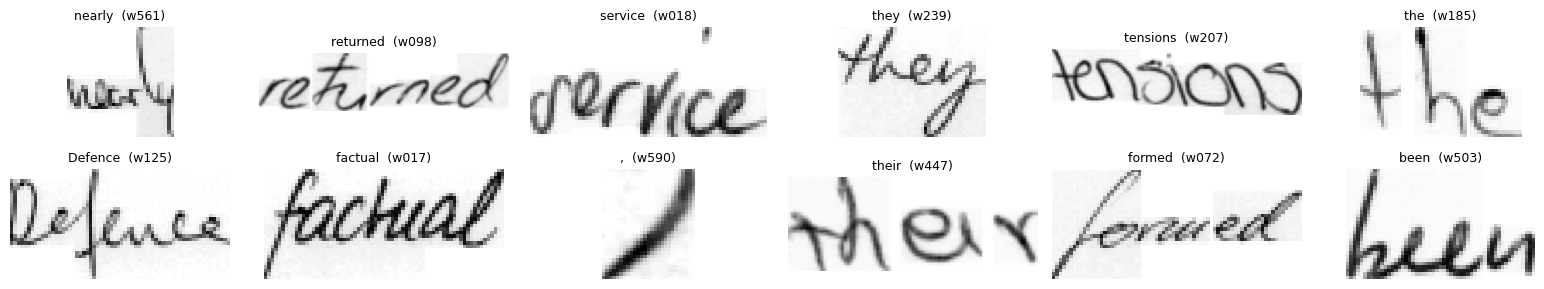

In [4]:
def load_word_img(path, h=CFG.img_h, max_w=CFG.max_real_w):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None or img.size == 0 or img.shape[0] < 2 or img.shape[1] < 2: return None
    hh, ww = img.shape
    nw = int(np.clip(round(ww * h / hh), 4, max_w))
    return cv2.resize(img, (nw, h), interpolation=cv2.INTER_AREA)

def _load(it): return load_word_img(it[3])

def find_existing_cache():
    cands = [os.path.join(CACHE_DIR, 'iam_h32.pkl')] + glob.glob(os.path.join(CFG.input_root, '*', 'cache', 'iam_h32.pkl')) \
            + glob.glob(os.path.join(CFG.input_root, '*', '*', 'cache', 'iam_h32.pkl'))
    for c in cands:
        if os.path.exists(c): return c
    return None

cache_path = find_existing_cache()
cache_ok = False
if cache_path and not CFG.DEBUG:
    with open(cache_path, 'rb') as f: cache = pickle.load(f)
    if cache.get('only_ok') == CFG.only_ok and cache.get('max_word_len') == CFG.max_word_len:
        RECS = cache['recs']; cache_ok = True
        print('loaded image cache from', cache_path, '->', len(RECS), 'records')
if not cache_ok:
    if CFG.DEBUG: items = items[:4000]
    t0 = time.time()
    with Pool(max(1, os.cpu_count())) as pool:
        imgs = list(pool.imap(_load, items, chunksize=256))
    RECS = [dict(id=it[0], text=it[1], writer=it[2], img=im) for it, im in zip(items, imgs) if im is not None]
    print(f'loaded {len(RECS)} images in {time.time()-t0:.0f}s')
    if not CFG.DEBUG:
        with open(os.path.join(CACHE_DIR, 'iam_h32.pkl'), 'wb') as f:
            pickle.dump(dict(recs=RECS, only_ok=CFG.only_ok, max_word_len=CFG.max_word_len), f, protocol=4)
del items, raw_words

# quick look
fig, axs = plt.subplots(2, 6, figsize=(16, 3))
for ax, r in zip(axs.ravel(), random.sample(RECS, 12)):
    ax.imshow(r['img'], cmap='gray'); ax.set_title(f"{r['text']}  (w{r['writer']})", fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Checkpoint detection, charset & writer split
If a checkpoint exists we reuse **its** charset and writer split so that resuming is consistent.

In [5]:
def find_checkpoint():
    if CFG.resume_path and os.path.exists(CFG.resume_path): return CFG.resume_path
    cands = [os.path.join(CKPT_DIR, 'last.pt')]
    cands += glob.glob(os.path.join(CFG.input_root, '*', 'checkpoints', 'last.pt'))
    cands += glob.glob(os.path.join(CFG.input_root, '*', '*', 'checkpoints', 'last.pt'))
    cands += glob.glob(os.path.join(CFG.input_root, '*', '*', '*', 'checkpoints', 'last.pt'))
    cands = [c for c in cands if os.path.exists(c)]
    return max(cands, key=os.path.getmtime) if cands else None

RESUME = find_checkpoint()
CKPT = torch.load(RESUME, map_location='cpu', weights_only=False) if RESUME else None
if CKPT is not None and CKPT.get('version') != CKPT_VERSION:
    print(f"found a checkpoint from an older notebook version ({CKPT.get('version')}) -> IGNORED, training starts fresh")
    CKPT, RESUME = None, None
print('resume from:', RESUME)

if CKPT is not None:
    CHARSET = CKPT['charset']; TRAIN_WRITERS = CKPT['train_writers']; TEST_WRITERS = CKPT['test_writers']
else:
    CHARSET = ''.join(sorted(set(''.join(r['text'] for r in RECS))))
    cnt = Counter(r['writer'] for r in RECS)
    writers = sorted(w for w, c in cnt.items() if c >= CFG.min_words_per_writer)
    rng = random.Random(CFG.seed); rng.shuffle(writers)
    n_test = max(2, int(len(writers) * CFG.test_writer_frac))
    TEST_WRITERS, TRAIN_WRITERS = sorted(writers[:n_test]), sorted(writers[n_test:])

RECS = [r for r in RECS if all(c in CHARSET for c in r['text'])]
CHAR2IDX = {c: i + 1 for i, c in enumerate(CHARSET)}      # 0 = CTC blank
N_CLASSES = len(CHARSET) + 1
W2I = {w: i for i, w in enumerate(TRAIN_WRITERS)}
N_WRITERS = len(TRAIN_WRITERS)

train_set_w, test_set_w = set(TRAIN_WRITERS), set(TEST_WRITERS)
train_idx = [i for i, r in enumerate(RECS) if r['writer'] in train_set_w]
test_idx  = [i for i, r in enumerate(RECS) if r['writer'] in test_set_w]
rng = random.Random(CFG.seed); rng.shuffle(train_idx)
n_val = min(max(64, int(len(train_idx) * CFG.val_frac)), len(train_idx) // 5)
val_idx, train_idx = sorted(train_idx[:n_val]), sorted(train_idx[n_val:])

BY_WRITER = defaultdict(list)
for i in train_idx: BY_WRITER[RECS[i]['writer']].append(i)
BY_WRITER_TEST = defaultdict(list)
for i in test_idx: BY_WRITER_TEST[RECS[i]['writer']].append(i)

# lexicon of target words for the generator (unique words containing at least one letter/digit)
LEXICON = sorted(set(RECS[i]['text'] for i in train_idx if any(c.isalnum() for c in RECS[i]['text'])))
print(f'charset ({len(CHARSET)}): {CHARSET}')
print(f'train writers {len(TRAIN_WRITERS)} | test writers {len(TEST_WRITERS)} | train words {len(train_idx)} | val {len(val_idx)} | test words {len(test_idx)} | lexicon {len(LEXICON)}')

resume from: None
charset (79):  !"#&'()*+,-./0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
train writers 440 | test writers 207 | train words 62231 | val 3275 | test words 30235 | lexicon 9459


## 3. Visual archetypes (GNU Unifont 16×16 glyphs)
Each character is rendered with GNU Unifont as a 16×16 binary image, flattened to 256 values and **linearly projected** to the query embedding. Because the query is computed from the glyph *shape*, the model can also take characters it rarely/never saw (the paper's long-tail argument).

The notebook tries: (1) a `unifont*.hex(.gz)` file you attached as input, (2) download from unifoundry/GNU mirrors, (3) fallback: render with *DejaVu Sans Mono* (still works, just not the exact paper glyphs).

Unifont downloaded from https://unifoundry.com/pub/unifont/unifont-15.1.05/font-builds/unifont-15.1.05.hex.gz -> 57084 glyphs


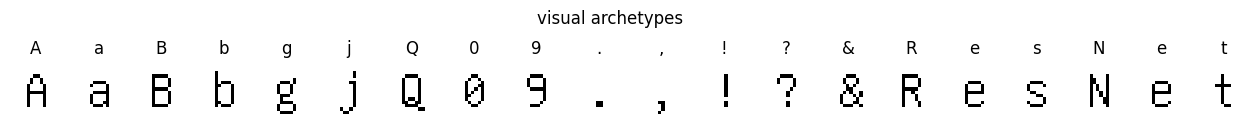

In [6]:
UNIFONT_URLS = [
    'https://unifoundry.com/pub/unifont/unifont-15.1.05/font-builds/unifont-15.1.05.hex.gz',
    'https://unifoundry.com/pub/unifont/unifont-15.1.04/font-builds/unifont-15.1.04.hex.gz',
    'https://unifoundry.com/pub/unifont/unifont-15.0.06/font-builds/unifont-15.0.06.hex.gz',
    'https://ftp.gnu.org/gnu/unifont/unifont-15.1.05/unifont-15.1.05.tar.gz',
]

def parse_unifont_hex(lines):
    glyphs = {}
    for line in lines:
        line = line.strip()
        if ':' not in line: continue
        cp, data = line.split(':', 1)
        try: cp = int(cp, 16)
        except ValueError: continue
        g = np.zeros((16, 16), np.uint8)
        if len(data) == 32:            # half-width glyph: 16 rows x 8 bits -> centre it in 16x16
            for r in range(16):
                bits = int(data[2*r:2*r+2], 16)
                for c in range(8): g[r, 4 + c] = (bits >> (7 - c)) & 1
        elif len(data) == 64:          # full-width: 16 rows x 16 bits
            for r in range(16):
                bits = int(data[4*r:4*r+4], 16)
                for c in range(16): g[r, c] = (bits >> (15 - c)) & 1
        else: continue
        glyphs[cp] = g
    return glyphs

def load_unifont():
    local = glob.glob(os.path.join(CFG.input_root, '**', 'unifont*.hex*'), recursive=False) + \
            glob.glob(os.path.join(CFG.input_root, '*', 'unifont*.hex*')) + glob.glob(os.path.join(CACHE_DIR, 'unifont*.hex*'))
    for p in local:
        try:
            op = gzip.open if p.endswith('.gz') else open
            with op(p, 'rt', encoding='utf-8', errors='ignore') as f: g = parse_unifont_hex(f)
            if len(g) > 1000: print('Unifont loaded from', p); return g
        except Exception as e: print('could not read', p, e)
    for url in UNIFONT_URLS:
        try:
            data = urllib.request.urlopen(url, timeout=30).read()
            if url.endswith('.tar.gz'):
                import tarfile
                tf = tarfile.open(fileobj=io.BytesIO(data))
                m = [m for m in tf.getmembers() if re.search(r'font/plane00/unifont\.hex$', m.name) or m.name.endswith('unifont.hex')]
                text = tf.extractfile(m[0]).read().decode('utf-8', 'ignore')
            else:
                text = gzip.decompress(data).decode('utf-8', 'ignore')
            g = parse_unifont_hex(text.splitlines())
            if len(g) > 1000:
                with gzip.open(os.path.join(CACHE_DIR, 'unifont.hex.gz'), 'wt') as f: f.write(text)
                print('Unifont downloaded from', url, '->', len(g), 'glyphs'); return g
        except Exception as e:
            print('download failed:', url, '|', type(e).__name__)
    print('WARNING: GNU Unifont not available -> falling back to DejaVu Sans Mono rendering')
    return None

class VisualArchetypes:
    def __init__(self):
        self.hex = load_unifont()
        self.cache = {}
        self.font = None
        if self.hex is None:
            from matplotlib import font_manager
            self.font = ImageFont.truetype(font_manager.findfont('DejaVu Sans Mono'), 15)

    def glyph(self, ch):
        if ch in self.cache: return self.cache[ch]
        if self.hex is not None and ord(ch) in self.hex:
            g = self.hex[ord(ch)].astype(np.float32)
        else:
            if self.font is None:
                from matplotlib import font_manager
                self.font = ImageFont.truetype(font_manager.findfont('DejaVu Sans Mono'), 15)
            im = Image.new('L', (16, 16), 0); d = ImageDraw.Draw(im)
            l, t, r, b = d.textbbox((0, 0), ch, font=self.font)
            d.text(((16 - (r - l)) / 2 - l, (16 - (b - t)) / 2 - t), ch, fill=255, font=self.font)
            g = (np.array(im) > 100).astype(np.float32)
        g = g.reshape(-1)
        self.cache[ch] = g
        return g

    def encode(self, texts):
        # texts -> glyphs [N, kmax, 256] float, mask [N, kmax] bool
        k = max(len(t) for t in texts)
        G = np.zeros((len(texts), k, 256), np.float32); M = np.zeros((len(texts), k), bool)
        for i, t in enumerate(texts):
            for j, ch in enumerate(t):
                G[i, j] = self.glyph(ch); M[i, j] = True
        return torch.from_numpy(G), torch.from_numpy(M)

ARCH = VisualArchetypes()
for ch in CHARSET: ARCH.glyph(ch)           # pre-compute (shared with DataLoader workers)

fig, axs = plt.subplots(1, 20, figsize=(16, 1.2))
for ax, ch in zip(axs, 'AaBbgjQ09.,!?&ResNet'):
    ax.imshow(ARCH.glyph(ch).reshape(16, 16), cmap='gray_r'); ax.set_title(ch); ax.axis('off')
plt.suptitle('visual archetypes', y=1.15); plt.show()

## 4. Datasets & batching

In [7]:
def style_format(a, W=CFG.style_w):
    # uint8 HxW (white background) -> HxW_style : squeeze if too wide, pad with white otherwise
    h, w = a.shape
    if w > W: return cv2.resize(a, (W, h), interpolation=cv2.INTER_AREA)
    out = np.full((h, W), 255, np.uint8); out[:, :w] = a
    return out

def aligned_img(a, text):
    # real word -> 32 x (16 * len(text)), the same geometry as a generated word (no aspect-ratio shortcut for D)
    if not CFG.real_char_aligned: return a
    return cv2.resize(a, (max(CFG.char_w, CFG.char_w * len(text)), CFG.img_h), interpolation=cv2.INTER_AREA)

def real_img(i):
    return aligned_img(RECS[i]['img'], RECS[i]['text'])

def u8_to_t(a):            # uint8 (white=255) -> float in [-1, 1] (white = +1)
    return torch.from_numpy(np.ascontiguousarray(a)).float().div_(127.5).sub_(1.0)

def pad_batch(imgs, multiple=16):
    # list of uint8 HxW -> tensor [N,1,H,Wmax] padded with white, widths [N]
    widths = torch.tensor([a.shape[1] for a in imgs], dtype=torch.long)
    W = int(math.ceil(widths.max().item() / multiple) * multiple)
    out = torch.ones(len(imgs), 1, imgs[0].shape[0], W)
    for i, a in enumerate(imgs): out[i, 0, :, :a.shape[1]] = u8_to_t(a)
    return out, widths

def encode_labels(texts):
    targets = torch.tensor([CHAR2IDX[c] for t in texts for c in t if c in CHAR2IDX], dtype=torch.long)
    lens = torch.tensor([sum(c in CHAR2IDX for c in t) for t in texts], dtype=torch.long)
    return targets, lens

def make_style_tensor(rec_indices, by_recs=None):
    by_recs = by_recs or RECS
    return torch.stack([u8_to_t(style_format(by_recs[i]['img'])) for i in rec_indices])[:, None]   # [P,1,H,W]

class GANDataset(Dataset):
    # one item = one writer: P style images, n_real real words (with labels), n_fake target strings
    def __init__(self, length=10**8):
        self.writers = [w for w in TRAIN_WRITERS if len(BY_WRITER[w]) > 0]
        self.length = length
    def __len__(self): return self.length
    def __getitem__(self, _):
        w = random.choice(self.writers)
        pool = BY_WRITER[w]
        sidx = random.sample(pool, CFG.num_style) if len(pool) >= CFG.num_style else random.choices(pool, k=CFG.num_style)
        ridx = random.choices(pool, k=CFG.n_real)
        return dict(style=np.stack([style_format(RECS[i]['img']) for i in sidx]),
                    writer=W2I[w],
                    real=[real_img(i) for i in ridx], real_txt=[RECS[i]['text'] for i in ridx],
                    fake_txt=[random.choice(LEXICON) for _ in range(CFG.n_fake)])

def gan_collate(batch):
    B = len(batch)
    style = torch.from_numpy(np.stack([b['style'] for b in batch])).float().div_(127.5).sub_(1.0)[:, :, None]  # [B,P,1,H,W]
    writer = torch.tensor([b['writer'] for b in batch])
    real, real_w = pad_batch([im for b in batch for im in b['real']])
    real_txt = [t for b in batch for t in b['real_txt']]
    rt, rl = encode_labels(real_txt)
    fake_txt = [t for b in batch for t in b['fake_txt']]
    glyphs, gmask = ARCH.encode(fake_txt)
    ft, fl = encode_labels(fake_txt)
    k = glyphs.shape[1]
    return dict(style=style, writer=writer,
                real=real, real_w=real_w, real_writer=writer.repeat_interleave(CFG.n_real), real_t=rt, real_l=rl,
                glyphs=glyphs.view(B, CFG.n_fake, k, 256), gmask=gmask.view(B, CFG.n_fake, k),
                fake_txt=fake_txt, fake_writer=writer.repeat_interleave(CFG.n_fake), fake_t=ft, fake_l=fl,
                fake_w=gmask.sum(1) * CFG.char_w)

class RealDataset(Dataset):
    # single real words, used for stage-1 pre-training and validation
    def __init__(self, idx): self.idx = idx
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        r = RECS[self.idx[i]]
        return real_img(self.idx[i]), style_format(r['img']), r['text'], W2I.get(r['writer'], -1)

def real_collate(batch):
    imgs, w = pad_batch([b[0] for b in batch])
    st = torch.stack([u8_to_t(b[1]) for b in batch])[:, None]
    t, l = encode_labels([b[2] for b in batch])
    return dict(img=imgs, w=w, style=st, texts=[b[2] for b in batch], t=t, l=l, writer=torch.tensor([b[3] for b in batch]))

# sanity check
_b = gan_collate([GANDataset()[0] for _ in range(2)])
print({k: (tuple(v.shape) if torch.is_tensor(v) else len(v)) for k, v in _b.items()})

{'style': (2, 15, 1, 32, 128), 'writer': (2,), 'real': (4, 1, 32, 96), 'real_w': (4,), 'real_writer': (4,), 'real_t': (12,), 'real_l': (4,), 'glyphs': (2, 4, 12, 256), 'gmask': (2, 4, 12), 'fake_txt': 8, 'fake_writer': (8,), 'fake_t': (61,), 'fake_l': (8,), 'fake_w': (8,)}


## 5. Models
* **StyleEncoder** = ResNet-50 backbone (ImageNet weights, grayscale stem, `conv1 … layer3` → 1024 ch × 2 × W/16, 1×1 projection to d = 512 → a 2 × 8 grid of tokens per 32×128 image; `layer4` is dropped because at 32 px height it would collapse everything to one row) + learned token positions + 3-layer Transformer encoder. 15 images × 16 tokens = 240 style vectors **S_w**.
* **Generator** = StyleEncoder + visual-archetype queries + 3-layer Transformer decoder + noise + Linear(512→8192) + 4 residual up-sampling blocks + tanh.
* **Discriminator** D (spectral-norm residual CNN, hinge loss, masked over padding), **HTR recognizer** R (CRNN + CTC), **writer classifier** W (ResNet-18).

In [8]:
def _tv_model(fn, weights):
    try:
        return fn(weights=weights if CFG.imagenet_pretrained else None)
    except Exception as e:
        print('could not download ImageNet weights (internet off?) -> random init.', type(e).__name__)
        return fn(weights=None)

def gray_conv1(conv):
    c = nn.Conv2d(1, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=False)
    c.weight.data.copy_(conv.weight.data.sum(1, keepdim=True))
    return c

def sinusoid(n, d):
    pos = torch.arange(n).float()[:, None]; i = torch.arange(0, d, 2).float()
    pe = torch.zeros(n, d); div = torch.exp(-math.log(10000.0) * i / d)
    pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
    return pe

class ResNet50Backbone(nn.Module):
    # ResNet-50 adapted to 32-px-high grayscale word images.
    def __init__(self, d_model):
        super().__init__()
        r = _tv_model(torchvision.models.resnet50, torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        self.stem = nn.Sequential(gray_conv1(r.conv1), r.bn1, r.relu, r.maxpool)   # H/4
        self.layer1, self.layer2, self.layer3 = r.layer1, r.layer2, r.layer3          # H/4, H/8, H/16 ; 1024 ch
        # layer4 is dropped: at 32 px height it would collapse the feature map to a single row
        self.proj = nn.Conv2d(1024, d_model, 1)                                         # 1024 -> d = 512
    def features(self, x):             # [N,1,32,W] -> [N,1024,2,W/16]
        return self.layer3(self.layer2(self.layer1(self.stem(x))))
    def forward(self, x):
        return self.proj(self.features(x))

class StyleEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.backbone = ResNet50Backbone(cfg.d_model)
        self.tok_pos = nn.Parameter(torch.randn(256, cfg.d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(cfg.d_model, cfg.n_heads, cfg.ff_dim, cfg.dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, cfg.enc_layers, enable_nested_tensor=False)
    def forward(self, style):          # style [B,P,1,H,W] -> S [B, P*t, d]
        B, P = style.shape[:2]
        f = self.backbone(style.flatten(0, 1))           # [B*P, d, h, w]
        f = f.flatten(2).transpose(1, 2)                 # [B*P, t, d]   (flatten h*w, as in the paper)
        f = f + self.tok_pos[:f.shape[1]]
        return self.encoder(f.reshape(B, -1, f.shape[-1]))

class ResBlockUp(nn.Module):
    def __init__(self, cin, cout, scale=None):
        super().__init__()
        self.scale = scale
        self.bn1, self.c1 = nn.BatchNorm2d(cin), nn.Conv2d(cin, cout, 3, 1, 1)
        self.bn2, self.c2 = nn.BatchNorm2d(cout), nn.Conv2d(cout, cout, 3, 1, 1)
        self.sc = nn.Conv2d(cin, cout, 1)
    def forward(self, x):
        h = F.relu(self.bn1(x))
        if self.scale:
            h = F.interpolate(h, scale_factor=self.scale, mode='nearest')
            x = F.interpolate(x, scale_factor=self.scale, mode='nearest')
        h = self.c2(F.relu(self.bn2(self.c1(h))))
        return h + self.sc(x)

class Generator(nn.Module):
    def __init__(self, cfg, n_writers):
        super().__init__()
        self.cfg = cfg
        self.freeze_backbone = False
        self.style_encoder = StyleEncoder(cfg)
        self.style_head = nn.Linear(cfg.d_model, n_writers)     # writer classifier on mean style vector (training only)
        self.style_proj = nn.Linear(cfg.d_model, cfg.d_model)    # global style path into every character token
        self.query_proj = nn.Linear(256, cfg.d_model)            # visual archetype -> query (256 x d params)
        self.query_norm = nn.LayerNorm(cfg.d_model)              # puts the character embedding at norm ~sqrt(d)
        self.register_buffer('qpos', sinusoid(128, cfg.d_model), persistent=False)
        layer = nn.TransformerDecoderLayer(cfg.d_model, cfg.n_heads, cfg.ff_dim, cfg.dropout, batch_first=True)
        self.decoder = nn.TransformerDecoder(layer, cfg.dec_layers)
        self.fc = nn.Linear(cfg.d_model, 512 * 4 * 4)            # k x 8192  ->  512 x 4 x 4k
        self.conv = nn.Sequential(
            ResBlockUp(512, 256, (2, 2)),    #  8 x  8k
            ResBlockUp(256, 128, (2, 2)),    # 16 x 16k
            ResBlockUp(128, 64, (2, 1)),     # 32 x 16k
            ResBlockUp(64, 64, None),
            nn.BatchNorm2d(64), nn.ReLU(), nn.Conv2d(64, 1, 3, 1, 1), nn.Tanh())

    def decode(self, S, glyphs, mask, noise=True):
        # S [N,T,d] style vectors, glyphs [N,k,256], mask [N,k] (True = real char) -> images [N,1,32,16k]
        N, k, _ = glyphs.shape
        # NOTE (fix after run 1): an un-normalised glyph embedding (norm ~4) was swamped by the positional encoding
        # (norm 16) and by the style vectors, so all characters looked alike to the decoder -> mode collapse.
        c = self.query_norm(self.query_proj(glyphs))             # character content, norm ~22
        q = c + 0.5 * self.qpos[:k]                              # + position (norm ~8)
        h = self.decoder(q, S, tgt_key_padding_mask=~mask) + c   # content skip: character identity always reaches the image decoder
        h = h + self.style_proj(S.mean(1, keepdim=True))         # global style skip: writer identity always reaches it too
        if noise and self.cfg.noise_std > 0:
            h = h + self.cfg.noise_std * torch.randn_like(h)
        x = self.fc(h).view(N, k, 512, 4, 4).permute(0, 2, 3, 1, 4).reshape(N, 512, 4, 4 * k)
        img = self.conv(x)
        col = mask.repeat_interleave(self.cfg.char_w, 1)[:, None, None, :]
        return torch.where(col, img, torch.ones_like(img))       # padded characters -> white

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone: self.style_encoder.backbone.eval()   # frozen BN statistics
        return self

    def forward(self, style, glyphs, mask, noise=True):
        # style [B,P,1,H,W], glyphs [B,M,k,256], mask [B,M,k] -> images [B*M,1,32,16k], S [B,T,d]
        S = self.style_encoder(style)
        B, M = glyphs.shape[:2]
        imgs = self.decode(S.repeat_interleave(M, 0), glyphs.flatten(0, 1), mask.flatten(0, 1), noise)
        return imgs, S

SN = nn.utils.spectral_norm
class DBlock(nn.Module):
    def __init__(self, cin, cout, down):
        super().__init__()
        self.c1, self.c2, self.sc = SN(nn.Conv2d(cin, cout, 3, 1, 1)), SN(nn.Conv2d(cout, cout, 3, 1, 1)), SN(nn.Conv2d(cin, cout, 1))
        self.down = down
    def forward(self, x):
        h = self.c2(F.leaky_relu(self.c1(F.leaky_relu(x, 0.2)), 0.2))
        if self.down: h, x = F.avg_pool2d(h, self.down), F.avg_pool2d(x, self.down)
        return h + self.sc(x)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.inp = SN(nn.Conv2d(1, 64, 3, 1, 1))
        self.blocks = nn.Sequential(DBlock(64, 128, (2, 2)), DBlock(128, 256, (2, 2)), DBlock(256, 512, (2, 2)), DBlock(512, 512, (2, 1)))
        self.out = SN(nn.Conv2d(512, 1, 1))
    def forward(self, x, widths):      # patch logits, averaged over the non-padded area
        h = self.out(F.leaky_relu(self.blocks(self.inp(x)), 0.2))      # [N,1,2,W/8]
        valid = torch.arange(h.shape[-1], device=x.device)[None] < torch.ceil(widths.to(x.device).float() / 8)[:, None]
        m = valid[:, None, None, :].float()
        return (h * m).sum((1, 2, 3)) / (m.sum((1, 2, 3)) * h.shape[2]).clamp(min=1)

class CRNN(nn.Module):
    # HTR recognizer R: CNN (32 -> 1 px height, width / 4) + 2-layer BiLSTM + CTC head
    def __init__(self, n_classes):
        super().__init__()
        def cbr(i, o): return [nn.Conv2d(i, o, 3, 1, 1), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.cnn = nn.Sequential(*cbr(1, 64), nn.MaxPool2d(2), *cbr(64, 128), nn.MaxPool2d(2),
                                 *cbr(128, 256), *cbr(256, 256), nn.MaxPool2d((2, 1)),
                                 *cbr(256, 512), *cbr(512, 512), nn.MaxPool2d((2, 1)),
                                 nn.Conv2d(512, 512, (2, 1)), nn.BatchNorm2d(512), nn.ReLU(True))
        self.rnn = nn.LSTM(512, 256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(512, n_classes)
    def forward(self, x):              # -> log-probs [T, N, C]
        f = self.cnn(x).squeeze(2).permute(0, 2, 1).contiguous()
        f, _ = self.rnn(f)
        return self.fc(f).float().log_softmax(-1).permute(1, 0, 2)

class WriterClassifier(nn.Module):
    def __init__(self, n_writers):
        super().__init__()
        r = _tv_model(torchvision.models.resnet18, torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        self.body = nn.Sequential(gray_conv1(r.conv1), r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.fc = nn.Linear(512, n_writers)
    def forward(self, x): return self.fc(self.body(x).mean((2, 3)))

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

In [9]:
G = Generator(CFG, N_WRITERS).to(DEVICE)
D = Discriminator().to(DEVICE)
R = CRNN(N_CLASSES).to(DEVICE)
W = WriterClassifier(N_WRITERS).to(DEVICE)
BB_HEAD = nn.Linear(1024, N_WRITERS).to(DEVICE)          # writer head used only for stage-1 backbone pre-training
G_EMA = copy.deepcopy(G).eval() if CFG.use_ema else G
for p in G_EMA.parameters(): p.requires_grad_(False)
print(f'G {n_params(G):.1f}M (ResNet-50 backbone {n_params(G.style_encoder.backbone):.1f}M) | D {n_params(D):.1f}M | R {n_params(R):.1f}M | W {n_params(W):.1f}M')

bb_params = list(G.style_encoder.backbone.parameters()); bb_ids = {id(p) for p in bb_params}
opt_g = torch.optim.Adam([{'params': [p for p in G.parameters() if id(p) not in bb_ids], 'lr': CFG.lr_g},
                          {'params': bb_params, 'lr': CFG.lr_backbone}], betas=(0.0, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=CFG.lr_d, betas=(0.0, 0.999))
opt_aux = torch.optim.Adam(list(R.parameters()) + list(W.parameters()), lr=CFG.lr_aux)

STATE = dict(step=0, stage1_done=False, history=[], val_history=[], best_score=float('inf'), best_step=-1, best_metrics={})
if CKPT is not None:
    G.load_state_dict(CKPT['G']); D.load_state_dict(CKPT['D']); R.load_state_dict(CKPT['R']); W.load_state_dict(CKPT['W'])
    if CFG.use_ema and CKPT.get('G_ema') is not None: G_EMA.load_state_dict(CKPT['G_ema'])
    if CKPT.get('bb_head') is not None: BB_HEAD.load_state_dict(CKPT['bb_head'])
    for o, k in ((opt_g, 'opt_g'), (opt_d, 'opt_d'), (opt_aux, 'opt_aux')):
        if CKPT.get(k) is not None:
            try: o.load_state_dict(CKPT[k])
            except Exception as e: print('optimizer state not restored:', k, e)
    STATE.update(step=CKPT['step'], stage1_done=CKPT['stage1_done'], history=CKPT.get('history', []))
    STATE.update(CKPT.get('state', {}))
    # bring the best generator of the previous session along (it lives next to last.pt)
    _prev_best = os.path.join(os.path.dirname(RESUME), 'best_G.pt')
    if os.path.abspath(_prev_best) != os.path.abspath(BEST_PATH) and os.path.exists(_prev_best) and \
            torch.load(_prev_best, map_location='cpu', weights_only=False).get('version') == CKPT_VERSION:
        import shutil; shutil.copy(_prev_best, BEST_PATH); print('copied previous best_G.pt')
    print(f"resumed: step {STATE['step']}, stage1_done={STATE['stage1_done']}")
    del CKPT

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 217MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 241MB/s]


G 32.4M (ResNet-50 backbone 9.1M) | D 9.8M | R 8.2M | W 11.4M


## 6. Losses, metrics, checkpointing & visualisation helpers

In [10]:
CTC = nn.CTCLoss(blank=0, zero_infinity=True)

def ctc_loss(lp, widths, targets, tlens):
    T = lp.shape[0]
    in_lens = torch.clamp(widths // 4, 1, T).long()
    return CTC(lp, targets.to(lp.device), in_lens.cpu(), tlens.cpu())

def greedy_decode(lp, widths=None):
    best = lp.argmax(-1).t().cpu().numpy()                 # [N,T]
    out = []
    for n, seq in enumerate(best):
        if widths is not None: seq = seq[:max(1, int(widths[n]) // 4)]
        s, prev = [], 0
        for c in seq:
            if c != prev and c != 0: s.append(CHARSET[c - 1])
            prev = c
        out.append(''.join(s))
    return out

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def cer(preds, gts):
    return sum(levenshtein(p, g) for p, g in zip(preds, gts)) / max(1, sum(len(g) for g in gts))

def set_requires_grad(m, flag):
    for p in m.parameters(): p.requires_grad_(flag)

def bn_eval(m):
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm): mod.eval()

@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, pm in zip(ema.parameters(), model.parameters()): pe.lerp_(pm, 1 - decay)
    for be, bm in zip(ema.buffers(), model.buffers()): be.copy_(bm)

def to_style_format_t(imgs, widths, W=CFG.style_w):
    # torch version of style_format for generated images (keeps the autograd graph)
    out = []
    for i in range(imgs.shape[0]):
        x = imgs[i:i + 1, :, :, :int(widths[i])]
        if x.shape[-1] > W: x = F.interpolate(x, size=(x.shape[2], W), mode='bilinear', align_corners=False)
        else: x = F.pad(x, (0, W - x.shape[-1]), value=1.0)
        out.append(x)
    return torch.cat(out)

def save_checkpoint(path=None):
    path = path or os.path.join(CKPT_DIR, 'last.pt')
    tmp = path + '.tmp'
    torch.save(dict(G=G.state_dict(), G_ema=G_EMA.state_dict() if CFG.use_ema else None, D=D.state_dict(),
                    R=R.state_dict(), W=W.state_dict(), bb_head=BB_HEAD.state_dict(), opt_g=opt_g.state_dict(), opt_d=opt_d.state_dict(),
                    opt_aux=opt_aux.state_dict(), step=STATE['step'], stage1_done=STATE['stage1_done'],
                    history=STATE['history'], state=STATE, version=CKPT_VERSION, charset=CHARSET, train_writers=TRAIN_WRITERS, test_writers=TEST_WRITERS,
                    cfg={k: v for k, v in vars(CFG).items() if not k.startswith('_')}), tmp)
    os.replace(tmp, path)
    print(f"  [checkpoint saved: {path} | step {STATE['step']}]")

# ---------- turning generated words into a line / page ----------
def trim_word(img, thr=0.3, pad=2):
    # img: np float [-1,1] HxW -> crop white columns left/right
    ink = (img < thr).any(0)
    if not ink.any(): return img[:, :8]
    l, r = np.argmax(ink), len(ink) - np.argmax(ink[::-1])
    return img[:, max(0, l - pad):min(img.shape[1], r + pad)]

def compose_lines(word_imgs, words, max_width=900, gap=None, line_gap=6):
    H = word_imgs[0].shape[0]; gap = gap or int(H * 0.45)
    lines, cur, cur_w = [], [], 0
    for im, w in zip(word_imgs, words):
        if w == '\n':
            lines.append(cur); cur, cur_w = [], 0; continue
        im = trim_word(im)
        if cur and cur_w + gap + im.shape[1] > max_width:
            lines.append(cur); cur, cur_w = [], 0
        cur.append(im); cur_w += im.shape[1] + (gap if len(cur) > 1 else 0)
    lines.append(cur)
    rows = []
    for ln in lines:
        row = np.ones((H, max_width), np.float32)
        x = 0
        for im in ln:
            w = min(im.shape[1], max_width - x)
            if w <= 0: break
            row[:, x:x + w] = im[:, :w]; x += w + gap
        rows += [row, np.ones((line_gap, max_width), np.float32)]
    page = np.concatenate(rows, 0)
    used = np.where((page < 0.3).any(0))[0]
    return page[:, :used.max() + 10] if len(used) else page

@torch.no_grad()
def generate_words(gen, style, words, noise=True, chunk=64):
    # style [P,1,H,W] tensor, words list[str] -> list of np images in [-1,1]
    gen.eval()
    S = gen.style_encoder(style[None].to(DEVICE))
    out = []
    for i in range(0, len(words), chunk):
        ws = words[i:i + chunk]
        g, m = ARCH.encode(ws)
        imgs = gen.decode(S.expand(len(ws), -1, -1), g.to(DEVICE), m.to(DEVICE), noise=noise)
        for j, w in enumerate(ws): out.append(imgs[j, 0, :, :len(w) * CFG.char_w].cpu().numpy())
    return out

def write_text(gen, style, text, max_width=900, noise=True, seed=None):
    if seed is not None: torch.manual_seed(seed)
    tokens = []
    for li, line in enumerate(text.split('\n')):
        if li > 0: tokens.append('\n')
        tokens += line.split()
    words = [t for t in tokens if t != '\n']
    if not words: return np.ones((CFG.img_h, 64), np.float32)
    imgs = iter(generate_words(gen, style, words, noise=noise))
    word_imgs = [next(imgs) if t != '\n' else None for t in tokens]
    return compose_lines([im if im is not None else np.ones((CFG.img_h, 1)) for im in word_imgs], tokens, max_width)

# fixed style sets for monitoring: 4 unseen (test) writers + 2 training writers
_rng = random.Random(0)
_cands = [w for w in TEST_WRITERS if len(BY_WRITER_TEST[w]) >= 5]
_mon_writers = _rng.sample(_cands, min(4, len(_cands))) + _rng.sample(TRAIN_WRITERS, min(2, len(TRAIN_WRITERS)))
def _style_for(w, rng=_rng):
    pool = BY_WRITER_TEST[w] if w in test_set_w else BY_WRITER[w]
    idx = rng.sample(pool, CFG.num_style) if len(pool) >= CFG.num_style else rng.choices(pool, k=CFG.num_style)
    return make_style_tensor(idx), idx
FIXED_STYLES = [(w,) + _style_for(w) for w in _mon_writers]
SAMPLE_TEXT = 'The quick brown fox jumps over the lazy dog'

@torch.no_grad()
def show_samples(gen, step, show=False):
    gen.eval()
    fig, axs = plt.subplots(len(FIXED_STYLES), 2, figsize=(18, 1.3 * len(FIXED_STYLES)), gridspec_kw={'width_ratios': [1, 3]})
    for row, (w, st, idx) in enumerate(FIXED_STYLES):
        ref = np.concatenate([RECS[i]['img'] for i in idx[:4]], 1)
        axs[row, 0].imshow(ref, cmap='gray', vmin=0, vmax=255); axs[row, 0].set_ylabel(('TEST ' if w in test_set_w else 'train ') + w, fontsize=8)
        page = write_text(gen, st, SAMPLE_TEXT, max_width=1200, seed=0)
        axs[row, 1].imshow(page, cmap='gray', vmin=-1, vmax=1)
        for a in axs[row]: a.set_xticks([]); a.set_yticks([])
    axs[0, 0].set_title('style samples (real)'); axs[0, 1].set_title(f'generated - step {step}')
    plt.tight_layout()
    fig.savefig(os.path.join(SAMPLE_DIR, f'step_{step:07d}.png'), dpi=90)
    if show: plt.show()
    plt.close(fig)

## 6b. Evaluation metrics (used for validation during training and for the final report)
| Metric | What it measures | Better |
|---|---|---|
| **CER** | character error rate of the HTR recognizer R on generated words (edit distance / #chars) → is the *content* correct & legible? | ↓ |
| **WER** / word accuracy | fraction of generated words not recognised exactly | ↓ / ↑ |
| **Char precision / recall / F1** (macro & micro) + **character confusion matrix** | per-character alignment of recognised vs. target text | ↑ |
| **FID** | Fréchet Inception Distance between Inception-v3 features of real and generated words (paired: same text, same writer) | ↓ |
| **KID** | Kernel Inception Distance (unbiased MMD, cubic kernel) — more reliable than FID on small sets | ↓ |
| **GS** | Geometry Score (Khrulkov & Oseledets, 2018): compares the topology (persistent homology, witness complexes) of real vs generated feature manifolds | ↓ |
| **Writer-ID accuracy, balanced acc., precision / recall / F1 (macro & weighted), Cohen κ, MCC, top-5** + **confusion matrix** | the writer classifier W (trained on real data only) must recognise the *target writer* from the generated words → is the *style* correct? (seen writers) | ↑ |
| **Unseen-writer retrieval acc / P / R / F1** + confusion matrix | for writers never seen in training: does a set of generated words retrieve the right writer among all test writers (cosine similarity of W-features)? | ↑ |

FID/KID/GS need the Inception-v3 ImageNet weights (Internet ON). GS needs the `gudhi` package (installed automatically).

In [11]:
import subprocess, warnings
warnings.filterwarnings('ignore', module='sklearn')
try:
    import gudhi
except ImportError:
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gudhi'], check=True, timeout=900)
        import gudhi
    except Exception as e:
        gudhi = None; print('gudhi not available -> Geometry Score will be skipped:', repr(e))
from scipy.spatial.distance import cdist
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, cohen_kappa_score, matthews_corrcoef, top_k_accuracy_score)
import pandas as pd

def to_u8(a):
    return a if a.dtype == np.uint8 else ((np.clip(a, -1, 1) + 1) * 127.5).astype(np.uint8)

# ------------------------------------------------------------------ text metrics
EPS = '∅'
def wer(preds, gts):
    return sum(levenshtein(p.split(), g.split()) for p, g in zip(preds, gts)) / max(1, sum(len(g.split()) for g in gts))

def word_accuracy(preds, gts):
    return float(np.mean([p == g for p, g in zip(preds, gts)])) if gts else 0.0

def align(ref, hyp):
    # Levenshtein alignment -> list of (ref_char | EPS, hyp_char | EPS)
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), np.int32); D[:, 0] = np.arange(n + 1); D[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]))
    i, j, pairs = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            pairs.append((ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            pairs.append((ref[i - 1], EPS)); i -= 1
        else:
            pairs.append((EPS, hyp[j - 1])); j -= 1
    return pairs[::-1]

def char_metrics(preds, gts):
    pairs = [pr for g, h in zip(gts, preds) for pr in align(g, h)]
    tp, fp, fn = Counter(), Counter(), Counter()
    for r, h in pairs:
        if r == h: tp[r] += 1
        else:
            if r != EPS: fn[r] += 1
            if h != EPS: fp[h] += 1
    per = {}
    for c in sorted(set(tp) | set(fn)):
        P = tp[c] / (tp[c] + fp[c]) if tp[c] + fp[c] else 0.0
        Rc = tp[c] / (tp[c] + fn[c]) if tp[c] + fn[c] else 0.0
        per[c] = dict(precision=P, recall=Rc, f1=2 * P * Rc / (P + Rc) if P + Rc else 0.0, support=tp[c] + fn[c])
    TP, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    mP = TP / (TP + FP) if TP + FP else 0.0; mR = TP / (TP + FN) if TP + FN else 0.0
    summary = dict(char_precision_macro=float(np.mean([v['precision'] for v in per.values()])) if per else 0.0,
                   char_recall_macro=float(np.mean([v['recall'] for v in per.values()])) if per else 0.0,
                   char_f1_macro=float(np.mean([v['f1'] for v in per.values()])) if per else 0.0,
                   char_precision_micro=mP, char_recall_micro=mR, char_f1_micro=2 * mP * mR / (mP + mR) if mP + mR else 0.0)
    return summary, per, pairs

def text_metrics(preds, gts):
    cm, per, pairs = char_metrics(preds, gts)
    return dict(CER=cer(preds, gts), WER=wer(preds, gts), word_accuracy=word_accuracy(preds, gts), **cm), per, pairs

def plot_char_confusion(pairs, title, fname):
    chars = [c for c in string.ascii_lowercase if c in CHARSET] + [EPS]
    ix = {c: i for i, c in enumerate(chars)}
    M = np.zeros((len(chars), len(chars)))
    for r, h in pairs:
        if r in ix and h in ix: M[ix[r], ix[h]] += 1
    Mn = M / M.sum(1, keepdims=True).clip(min=1)
    plt.figure(figsize=(11, 9)); plt.imshow(Mn, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046)
    plt.xticks(range(len(chars)), chars); plt.yticks(range(len(chars)), chars)
    plt.xlabel('recognised character (∅ = deleted)'); plt.ylabel('target character (∅ = inserted)'); plt.title(title)
    plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, fname), dpi=100); plt.show()

# ------------------------------------------------------------------ classification metrics
def classification_metrics(y_true, y_pred, probs=None, n_classes=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    pM, rM, fM, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    pW, rW, fW, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    out = dict(accuracy=accuracy_score(y_true, y_pred), balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
               precision_macro=pM, recall_macro=rM, f1_macro=fM, precision_weighted=pW, recall_weighted=rW, f1_weighted=fW,
               cohen_kappa=cohen_kappa_score(y_true, y_pred), mcc=matthews_corrcoef(y_true, y_pred))
    if probs is not None and n_classes and n_classes > 5:
        out['top5_accuracy'] = top_k_accuracy_score(y_true, probs, k=5, labels=np.arange(n_classes))
    return {k: float(v) for k, v in out.items()}

def plot_confusion(y_true, y_pred, names, title, fname, zoom=15):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    top = labels[np.argsort(-cm.sum(1))[:zoom]]
    sub = confusion_matrix(y_true, y_pred, labels=top)
    fig, axs = plt.subplots(1, 2, figsize=(20, 8.5))
    im = axs[0].imshow(cmn, cmap='Blues', vmin=0, vmax=1, interpolation='nearest'); fig.colorbar(im, ax=axs[0], fraction=0.046)
    axs[0].set_title(f'{title}\nfull normalised confusion matrix ({len(labels)} classes)'); axs[0].set_xlabel('predicted'); axs[0].set_ylabel('true')
    axs[1].imshow(sub, cmap='Blues'); axs[1].set_title(f'zoom: {len(top)} most frequent classes (counts)')
    tn = [str(names[t]) for t in top]
    axs[1].set_xticks(range(len(top))); axs[1].set_xticklabels(tn, rotation=90); axs[1].set_yticks(range(len(top))); axs[1].set_yticklabels(tn)
    for i in range(len(top)):
        for j in range(len(top)):
            if sub[i, j]: axs[1].text(j, i, sub[i, j], ha='center', va='center', fontsize=8, color='white' if sub[i, j] > sub.max() / 2 else 'black')
    plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, fname), dpi=90); plt.show()

# ------------------------------------------------------------------ Inception features, FID, KID, GS
class InceptionFeatures:
    def __init__(self):
        self.model, self.pretrained = None, False
        try:
            m = torchvision.models.inception_v3(weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1); self.pretrained = True
        except Exception as e:
            print('Inception-v3 ImageNet weights unavailable (Internet off?) -> FID / KID / GS will be skipped.', type(e).__name__)
            if not CFG.DEBUG: return
            m = torchvision.models.inception_v3(weights=None, aux_logits=False, init_weights=False)
            print('  (DEBUG: random Inception only to exercise the code - values are meaningless)')
        m.fc = nn.Identity()
        self.model = m.eval().to(DEVICE)
        for q in self.model.parameters(): q.requires_grad_(False)
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    @property
    def ok(self): return self.model is not None
    @torch.no_grad()
    def __call__(self, imgs, bs=50):
        # imgs: list of word images (uint8 white=255, or float in [-1,1]) -> [N, 2048] features
        feats = []
        for i in range(0, len(imgs), bs):
            batch = []
            for a in imgs[i:i + bs]:
                t = torch.as_tensor(to_u8(a), dtype=torch.float32, device=DEVICE) / 255.0
                h, w = t.shape; sq = max(h, w)
                t = F.pad(t[None, None], ((sq - w) // 2, sq - w - (sq - w) // 2, (sq - h) // 2, sq - h - (sq - h) // 2), value=1.0)
                batch.append(F.interpolate(t, size=(299, 299), mode='bilinear', align_corners=False))
            x = torch.cat(batch).repeat(1, 3, 1, 1)
            feats.append(self.model((x - self.mean) / self.std).float().cpu())
        return torch.cat(feats).numpy().astype(np.float64)

def fid_score(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    tr_covmean = np.sqrt(np.clip(np.linalg.eigvals(s1 @ s2).real, 0, None)).sum()     # trace(sqrtm(s1 s2))
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)

def kid_score(f1, f2, n_subsets=10, subset_size=1000, seed=0):
    rng = np.random.RandomState(seed); d = f1.shape[1]; m = min(subset_size, len(f1), len(f2)); vals = []
    for _ in range(n_subsets):
        x = f1[rng.choice(len(f1), m, replace=False)]; y = f2[rng.choice(len(f2), m, replace=False)]
        kxx, kyy, kxy = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))

def _rlt(intervals, alpha_max, i_max=100):
    # relative living times: fraction of [0, alpha_max] during which exactly i 1-dimensional holes exist
    rlt = np.zeros(i_max)
    iv = np.asarray(intervals, float).reshape(-1, 2) if len(intervals) else np.zeros((0, 2))
    if len(iv) == 0: rlt[0] = 1.0; return rlt
    iv = np.clip(np.nan_to_num(iv, posinf=alpha_max), 0, alpha_max)
    pts = np.unique(np.concatenate([[0.0, alpha_max], iv.ravel()]))
    for a, b in zip(pts[:-1], pts[1:]):
        k = int(((iv[:, 0] <= (a + b) / 2) & (iv[:, 1] > (a + b) / 2)).sum())
        if k < i_max: rlt[k] += b - a
    return rlt / alpha_max

def mean_rlt(X, n_runs, L_0=64, i_max=100, seed=0):
    rng = np.random.RandomState(seed); gamma = 1.0 / 128 * 1000 / len(X); out = np.zeros((n_runs, i_max))
    for r in range(n_runs):
        L = X[rng.choice(len(X), L_0)]
        a = cdist(X, L); idx = np.argsort(a, 1); b = np.take_along_axis(a, idx, 1)
        table = [list(zip(ri.tolist(), di.tolist())) for ri, di in zip(idx, b)]
        alpha_max = float(a.max() * gamma)
        st = gudhi.WitnessComplex(nearest_landmark_table=table).create_simplex_tree(max_alpha_square=alpha_max, limit_dimension=2)
        st.persistence(homology_coeff_field=2)
        out[r] = _rlt(st.persistence_intervals_in_dimension(1), alpha_max, i_max)
    return out.mean(0)

def geometry_score(f_real, f_fake, n=None, runs=None, seed=0):
    if gudhi is None: return None
    n, runs = n or CFG.gs_n, runs or CFG.gs_runs
    rng = np.random.RandomState(seed)
    a = f_real[rng.choice(len(f_real), min(n, len(f_real)), replace=False)]
    b = f_fake[rng.choice(len(f_fake), min(n, len(f_fake)), replace=False)]
    return float(((mean_rlt(a, runs, seed=seed) - mean_rlt(b, runs, seed=seed + 1)) ** 2).sum())

INCEPTION = InceptionFeatures()

# ------------------------------------------------------------------ recogniser / writer-classifier wrappers
@torch.no_grad()
def recognize(imgs, bs=256):
    R.eval(); out = []
    for i in range(0, len(imgs), bs):
        x, w = pad_batch([to_u8(a) for a in imgs[i:i + bs]]); out += greedy_decode(R(x.to(DEVICE)), w)
    R.train(); return out

@torch.no_grad()
def writer_predict(imgs, bs=256):
    W.eval(); probs, feats = [], []
    for i in range(0, len(imgs), bs):
        x, _ = pad_batch([to_u8(a) for a in imgs[i:i + bs]])
        f = W.body(x.to(DEVICE)).mean((2, 3))
        probs.append(F.softmax(W.fc(f), 1).cpu()); feats.append(F.normalize(f, dim=1).cpu())
    W.train(); return torch.cat(probs).numpy(), torch.cat(feats).numpy()

# ------------------------------------------------------------------ paired generation (same text, same writer)
def sample_targets(pool, n, seed):
    return sorted(random.Random(seed).sample(pool, min(n, len(pool))))

@torch.no_grad()
def generate_paired(gen, target_idx, seed=0):
    # for every target word: style = 15 OTHER words of the same writer, content = the target's text
    rng = random.Random(seed); torch.manual_seed(seed)
    by_w = defaultdict(list)
    for i in target_idx: by_w[RECS[i]['writer']].append(i)
    out = dict(fake=[], real=[], texts=[], writers=[])
    for w in sorted(by_w):
        tids = by_w[w]; tset = set(tids)
        full = BY_WRITER_TEST[w] if w in test_set_w else BY_WRITER[w]
        pool = [i for i in full if i not in tset] or full
        sidx = rng.sample(pool, CFG.num_style) if len(pool) >= CFG.num_style else rng.choices(pool, k=CFG.num_style)
        out['fake'] += generate_words(gen, make_style_tensor(sidx), [RECS[i]['text'] for i in tids])
        out['real'] += [real_img(i) for i in tids]; out['texts'] += [RECS[i]['text'] for i in tids]; out['writers'] += [w] * len(tids)
    torch.seed()
    return out

# ------------------------------------------------------------------ quick validation + best-model tracking
QV_TARGETS = sample_targets(test_idx, CFG.quick_val_n, seed=1)
QV_STYLE_TARGETS = sample_targets(val_idx, CFG.style_val_n, seed=2)   # seen writers: W knows them
_QV_REAL_FEATS = None

def quick_val(gen):
    global _QV_REAL_FEATS
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    out = generate_paired(gen, QV_TARGETS, seed=0)
    preds = recognize(out['fake'])
    m = dict(cer=cer(preds, out['texts']), wer=wer(preds, out['texts']))
    # diversity: pixel std across different generated words (resized to 32x64). ~0 => mode collapse (all words look alike)
    stack = np.stack([cv2.resize(((np.clip(a, -1, 1) + 1) / 2).astype(np.float32), (64, CFG.img_h)) for a in out['fake'][:200]])
    m['diversity'] = float(stack.std(0).mean())
    if m['diversity'] < 0.03: print('  WARNING: generated words are almost identical (possible mode collapse)')
    if INCEPTION.ok:
        if _QV_REAL_FEATS is None: _QV_REAL_FEATS = INCEPTION(out['real'])
        m['fid'] = fid_score(_QV_REAL_FEATS, INCEPTION(out['fake']))
    # style: does the independent writer classifier W recognise the intended writer in the generated words?
    o2 = generate_paired(gen, QV_STYLE_TARGETS, seed=0)
    probs, _ = writer_predict(o2['fake'])
    y = np.array([W2I[w] for w in o2['writers']])
    m['style_acc'] = float((probs.argmax(1) == y).mean())
    m['style_top5'] = float((np.argsort(-probs, 1)[:, :5] == y[:, None]).any(1).mean())
    return m

def model_score(m):
    # lower = better: FID (realism) x (1 + CER) (legibility) x (1 + 2 * (1 - style accuracy)) (personalisation)
    base = m['fid'] * (1.0 + m['cer']) if 'fid' in m else 100.0 * m['cer']
    return base * (1.0 + 2.0 * (1.0 - m.get('style_acc', 0.0)))

def maybe_update_best(gen, m):
    m = dict(m, step=STATE['step'], score=model_score(m)); STATE['val_history'].append(m)
    improved = m['score'] < STATE['best_score']
    if improved:
        STATE.update(best_score=m['score'], best_step=STATE['step'], best_metrics=m)
        torch.save(dict(G=gen.state_dict(), step=STATE['step'], metrics=m, charset=CHARSET, version=CKPT_VERSION), BEST_PATH)
    print(f"  [validation @ step {STATE['step']}] " + ' '.join(f'{k}={v:.4f}' for k, v in m.items() if k != 'step') +
          ('  -> NEW BEST, saved best_G.pt' if improved else f"  (best score {STATE['best_score']:.4f} @ step {STATE['best_step']})"), flush=True)
    return improved

print('metrics ready | Inception:', 'pretrained' if INCEPTION.pretrained else ('random (DEBUG)' if INCEPTION.ok else 'unavailable'),
      '| gudhi (GS):', gudhi is not None)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 257MB/s] 


metrics ready | Inception: pretrained | gudhi (GS): True


## 7. Stage 1 — pre-train the ResNet-50 style backbone, the HTR recognizer and the writer classifier on real IAM words
* **Backbone**: writer classification on 32×128 style crops (the paper pre-trains its backbone to *recognise calligraphic style*; Table 1 shows IAM pre-training also helps).
* **R** (CTC) and **W** (writer CE) must already be decent before they can guide the generator.

In [12]:
@torch.no_grad()
def validate_stage1(max_batches=30):
    G.eval(); R.eval(); W.eval()
    dl = DataLoader(RealDataset(val_idx), batch_size=128, shuffle=False, collate_fn=real_collate, num_workers=2)
    preds, gts, acc_bb, acc_w, n = [], [], 0, 0, 0
    for bi, b in enumerate(dl):
        if bi >= max_batches: break
        img, st, wr = b['img'].to(DEVICE), b['style'].to(DEVICE), b['writer'].to(DEVICE)
        preds += greedy_decode(R(img), b['w']); gts += b['texts']
        acc_bb += (BB_HEAD(G.style_encoder.backbone.features(st).mean((2, 3))).argmax(1) == wr).sum().item()
        acc_w += (W(img).argmax(1) == wr).sum().item(); n += len(wr)
    G.train(); R.train(); W.train()
    return dict(htr_cer=cer(preds, gts), htr_wer=wer(preds, gts), backbone_writer_acc=acc_bb / n, W_writer_acc=acc_w / n), list(zip(gts[:8], preds[:8]))

def run_stage1():
    ds = RealDataset(train_idx)
    dl = DataLoader(ds, batch_size=CFG.pretrain_bs, shuffle=True, collate_fn=real_collate,
                    num_workers=CFG.num_workers, drop_last=True, pin_memory=True, persistent_workers=CFG.num_workers > 0)
    opt_bb = torch.optim.Adam([{'params': G.style_encoder.backbone.parameters(), 'lr': CFG.lr_backbone_pre},
                               {'params': BB_HEAD.parameters(), 'lr': 1e-3}])
    G.train(); R.train(); W.train()
    for ep in range(CFG.pretrain_epochs):
        t0, run = time.time(), defaultdict(float)
        for it, b in enumerate(dl):
            img, w, st, wr = b['img'].to(DEVICE, non_blocking=True), b['w'], b['style'].to(DEVICE, non_blocking=True), b['writer'].to(DEVICE)
            l_bb = F.cross_entropy(BB_HEAD(G.style_encoder.backbone.features(st).mean((2, 3))), wr)
            l_r = ctc_loss(R(img), w, b['t'], b['l'])
            l_w = F.cross_entropy(W(img), wr)
            opt_bb.zero_grad(set_to_none=True); opt_aux.zero_grad(set_to_none=True)
            (l_bb + l_r + l_w).backward()
            opt_bb.step(); opt_aux.step()
            for k, v in (('bb', l_bb), ('htr', l_r), ('wcls', l_w)): run[k] += v.item()
            if (it + 1) % 200 == 0 or (CFG.DEBUG and it % 10 == 0):
                print(f"  ep {ep+1} it {it+1}/{len(dl)} | " + ' '.join(f'{k} {v/(it+1):.3f}' for k, v in run.items()) + f' | {time.time()-t0:.0f}s')
            if CFG.DEBUG and it >= 30: break
        metrics, examples = validate_stage1()
        print(f'epoch {ep+1} done in {time.time()-t0:.0f}s | val: ' + ', '.join(f'{k}={v:.3f}' for k, v in metrics.items()))
        print('   HTR examples (gt -> pred):', examples)
    STATE['stage1_done'] = True
    save_checkpoint()

if not STATE['stage1_done']:
    run_stage1()
else:
    print('stage 1 already done (loaded from checkpoint):', validate_stage1()[0])

  ep 1 it 200/972 | bb 4.652 htr 4.090 wcls 5.094 | 40s
  ep 1 it 400/972 | bb 3.676 htr 3.357 wcls 4.516 | 77s
  ep 1 it 600/972 | bb 3.132 htr 2.874 wcls 4.089 | 116s
  ep 1 it 800/972 | bb 2.790 htr 2.505 wcls 3.774 | 155s
epoch 1 done in 191s | val: htr_cer=0.288, htr_wer=0.558, backbone_writer_acc=0.647, W_writer_acc=0.500
   HTR examples (gt -> pred): [('Mr.', 'Mr.'), ('resolution', 'enslelion'), ('be', 'he'), ('M Ps', 'wss'), ('the', 'the'), ('the', 'te'), ('nominees', 'woinees'), ('.', '.')]
  ep 2 it 200/972 | bb 1.214 htr 0.805 wcls 2.205 | 38s
  ep 2 it 400/972 | bb 1.187 htr 0.754 wcls 2.126 | 77s
  ep 2 it 600/972 | bb 1.163 htr 0.707 wcls 2.054 | 115s
  ep 2 it 800/972 | bb 1.144 htr 0.671 wcls 1.995 | 154s
epoch 2 done in 190s | val: htr_cer=0.166, htr_wer=0.388, backbone_writer_acc=0.709, W_writer_acc=0.599
   HTR examples (gt -> pred): [('Mr.', 'Mr.'), ('resolution', 'renletion'), ('be', 'he'), ('M Ps', 'MEs'), ('the', 'the'), ('the', 'the'), ('nominees', 'nominees'), 

## 8. Stage 2 — VATr adversarial training
**Personalisation**: the ResNet-50 backbone is frozen (it was writer-pre-trained in stage 1), a writer-classification loss on the style vectors keeps the style encoder from collapsing, and validation tracks **style accuracy**.

**Gradient balancing** (as in the HWT/VATr code): each loss is rescaled so that its gradient on the generated image has the same magnitude as a reference gradient (`a_htr`, `a_cls`, `a_cyc` in the log).
**Phase A – content warm-up** (`CFG.content_warmup_steps`, default 5 000): no discriminator; reference = HTR gradient, so the generator first learns to write the correct characters, with writer + cycle losses balanced to the same strength. **Phase B** switches the discriminator on; reference = adversarial gradient.

Each iteration of phase B:
1. **G** generates `n_fake` words per writer from its 15 style images.
2. **D** step — hinge loss: `max(0, 1 − D(real)) + max(0, 1 + D(fake))`.
3. **R / W** step on real words only (CTC + writer CE).
4. **G** step — `L = L_adv + L_HTR + L_class + L_cycle`, where `L_cycle = ‖E(X_w) − E(Y_w)‖₁` compares the (mean) style vectors of the real style set and of the generated words (the encoder is used with frozen weights for this term, so only the generator is pushed).

Every `CFG.eval_every` steps a **quick validation** on unseen writers computes FID and CER; the model with the best score (FID × (1 + CER) × (1 + 2·(1 − style accuracy))) is saved as **`checkpoints/best_G.pt`** — that is the model used for the final evaluation, generation and export.

Training stops automatically `CFG.final_eval_reserve_h` hours before the time budget, saving `checkpoints/last.pt`, so the evaluation / generation cells always finish in the same run. Just run the notebook again (with the previous output attached) to continue. Sample sheets go to `/kaggle/working/samples/`.

ResNet-50 style backbone frozen for stage 2 (writer-pre-trained in stage 1)
step     200 | D 0.000 R_real 0.558 W_real 3.572 G_adv 0.000 G_htr 1.291 G_cls 5.707 G_cyc 0.615 S_cls 4.883 a_htr 1.000 a_cls 0.362 a_cyc 4.174 | 1.99 it/s | 10.40 h left
step     400 | D 0.000 R_real 0.512 W_real 3.310 G_adv 0.000 G_htr 0.197 G_cls 3.517 G_cyc 0.655 S_cls 2.473 a_htr 1.000 a_cls 0.052 a_cyc 0.366 | 2.00 it/s | 10.38 h left
step     600 | D 0.000 R_real 0.446 W_real 3.143 G_adv 0.000 G_htr 0.139 G_cls 2.671 G_cyc 0.645 S_cls 1.130 a_htr 1.000 a_cls 0.041 a_cyc 0.244 | 2.00 it/s | 10.35 h left
step     800 | D 0.000 R_real 0.413 W_real 2.928 G_adv 0.000 G_htr 0.133 G_cls 2.271 G_cyc 0.658 S_cls 0.406 a_htr 1.000 a_cls 0.048 a_cyc 0.265 | 2.00 it/s | 10.32 h left
step    1000 | D 0.000 R_real 0.410 W_real 2.830 G_adv 0.000 G_htr 0.109 G_cls 1.724 G_cyc 0.618 S_cls 0.190 a_htr 1.000 a_cls 0.035 a_cyc 0.177 | 2.00 it/s | 10.29 h left
step    1200 | D 0.000 R_real 0.383 W_real 2.794 G_adv 0.000 G_h

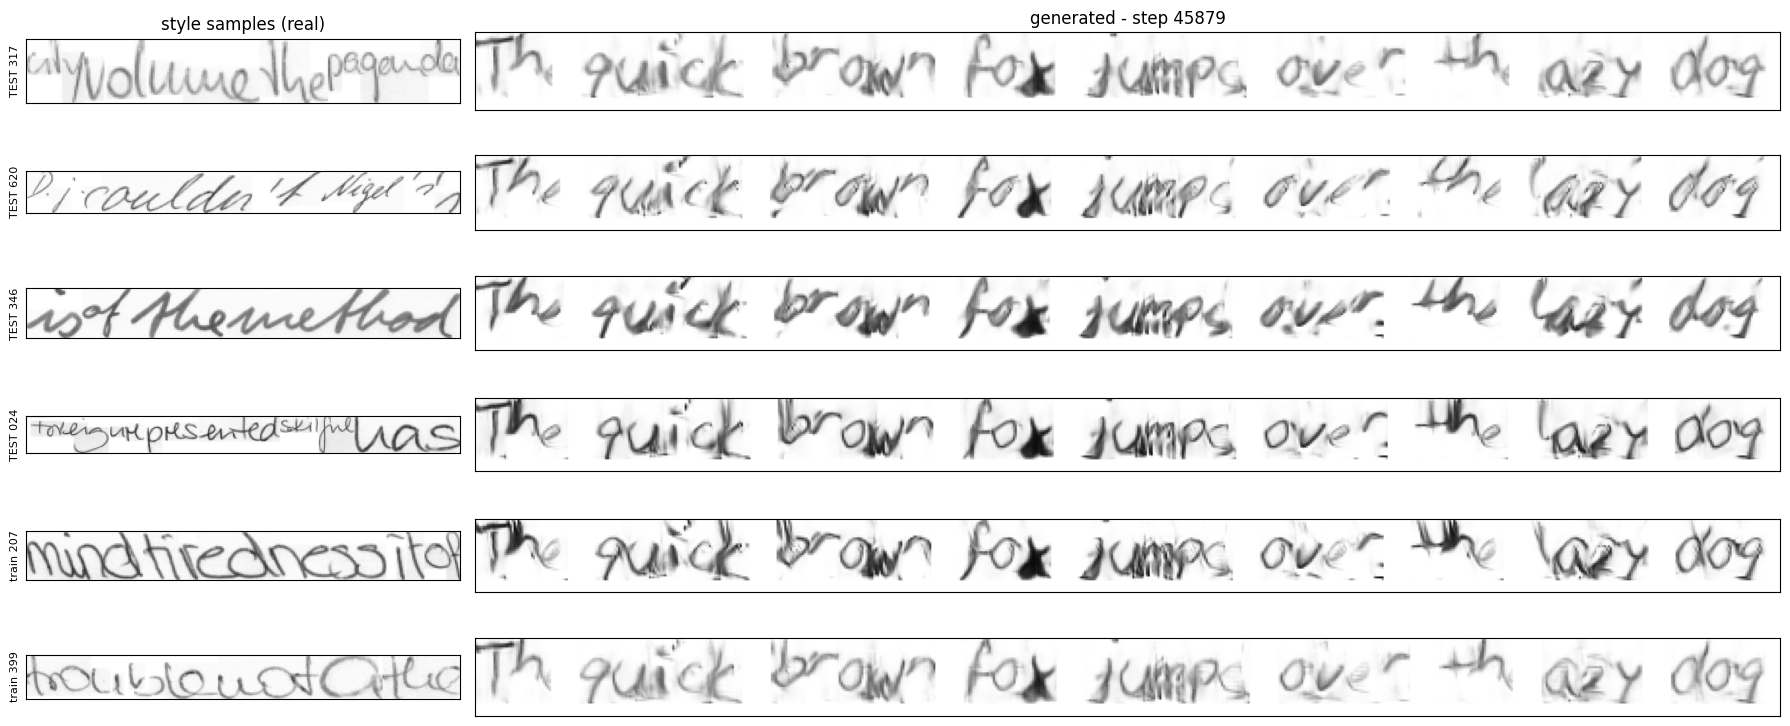

In [13]:
def train_step(b):
    enc = G.style_encoder
    style = b['style'].to(DEVICE, non_blocking=True)
    real, real_w = b['real'].to(DEVICE, non_blocking=True), b['real_w']
    glyphs, gmask = b['glyphs'].to(DEVICE), b['gmask'].to(DEVICE)
    fake_w = b['fake_w']

    # ---- 1. generate ----
    fake, S = G(style, glyphs, gmask)

    warmup = STATE['step'] < CFG.content_warmup_steps

    # ---- 2. discriminator (switched on after the content warm-up) ----
    set_requires_grad(D, True)
    if warmup:
        d_loss = torch.zeros((), device=DEVICE)
    else:
        d_loss = F.relu(1 - D(real, real_w)).mean() + F.relu(1 + D(fake.detach(), fake_w)).mean()
        opt_d.zero_grad(set_to_none=True); d_loss.backward(); opt_d.step()

    # ---- 3. recognizer + writer classifier on real data ----
    set_requires_grad(R, True); set_requires_grad(W, True); R.train(); W.train()
    r_loss = ctc_loss(R(real), real_w, b['real_t'], b['real_l'])
    w_loss = F.cross_entropy(W(real), b['real_writer'].to(DEVICE))
    opt_aux.zero_grad(set_to_none=True); (r_loss + w_loss).backward(); opt_aux.step()

    # ---- 4. generator ----
    set_requires_grad(D, False); set_requires_grad(R, False); set_requires_grad(W, False)
    bn_eval(R); W.eval()          # (R stays in train mode for cuDNN-LSTM backward; only its BN is frozen)
    g_adv = torch.zeros((), device=DEVICE) if warmup else -D(fake, fake_w).mean()
    g_htr = ctc_loss(R(fake), fake_w, b['fake_t'], b['fake_l'])
    g_cls = F.cross_entropy(W(fake), b['fake_writer'].to(DEVICE))
    # cycle consistency: style vectors of generated words should match those of the real style images
    enc.eval()
    frozen = {k: v.detach() for k, v in enc.named_parameters()}
    with torch.no_grad():
        s_real = functional_call(enc, frozen, (style,)).mean(1)
    fake_style = to_style_format_t(fake, fake_w).view(style.shape[0], CFG.n_fake, 1, CFG.img_h, CFG.style_w)
    s_fake = functional_call(enc, frozen, (fake_style,)).mean(1)
    g_cyc = F.l1_loss(s_fake, s_real)
    G.train()   # (re-applies the frozen-backbone eval mode)
    # Gradient balancing (as in the HWT / VATr code): every auxiliary loss is rescaled so that its gradient on the
    # generated image has the same std as a reference gradient. Without it, run 1 collapsed: the writer-classifier
    # gradient was ~200x larger than the HTR gradient, so the generator ignored the text completely.
    #   phase A (warm-up, no D): reference = HTR gradient   -> content is learnt first
    #   phase B (adversarial)  : reference = adversarial gradient
    a_htr = a_cls = a_cyc = torch.ones((), device=DEVICE)
    if CFG.grad_balance:
        def _gstd(loss):
            g = torch.autograd.grad(loss, fake, retain_graph=True, allow_unused=True)[0]
            return g.std() if g is not None else torch.zeros((), device=DEVICE)
        gh, gc, gy = _gstd(g_htr), _gstd(g_cls), _gstd(g_cyc)
        ref = gh if warmup else _gstd(g_adv)
        if not warmup: a_htr = (ref / (gh + 1e-8)).detach().clamp(max=1e3)
        a_cls = (ref / (gc + 1e-8)).detach().clamp(max=1e3)
        a_cyc = (ref / (gy + 1e-8)).detach().clamp(max=1e3)
    # style-encoder writer loss (on S, not on the image -> not balanced): prevents the collapse seen in run 2,
    # where all writers were mapped to the same style vector and the generator lost every trace of style
    s_cls = F.cross_entropy(G.style_head(S.mean(1)), b['writer'].to(DEVICE))
    g_loss = CFG.w_htr * a_htr * g_htr + CFG.w_cls * a_cls * g_cls + CFG.w_cyc * a_cyc * g_cyc + CFG.w_style_enc * s_cls
    if not warmup: g_loss = g_loss + CFG.w_adv * g_adv
    opt_g.zero_grad(set_to_none=True)
    if torch.isfinite(g_loss):                 # never let a NaN/inf batch corrupt the generator
        g_loss.backward()
        torch.nn.utils.clip_grad_norm_(G.parameters(), CFG.grad_clip)
        opt_g.step()
        if CFG.use_ema: ema_update(G_EMA, G, CFG.ema_decay if STATE['step'] > 1000 else 0.0)
    return {'D': d_loss.item(), 'R_real': r_loss.item(), 'W_real': w_loss.item(), 'G_adv': g_adv.item(),
            'G_htr': g_htr.item(), 'G_cls': g_cls.item(), 'G_cyc': g_cyc.item(), 'S_cls': s_cls.item(), 'a_htr': a_htr.item(), 'a_cls': a_cls.item(), 'a_cyc': a_cyc.item()}

def _reset_after_oom():
    for o in (opt_g, opt_d, opt_aux): o.zero_grad(set_to_none=True)
    set_requires_grad(D, True); set_requires_grad(R, True); set_requires_grad(W, True)
    G.train(); R.train(); W.train()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def gan_train():
    dl = DataLoader(GANDataset(), batch_size=CFG.batch_size, collate_fn=gan_collate, num_workers=CFG.num_workers,
                    pin_memory=True, persistent_workers=CFG.num_workers > 0, prefetch_factor=4 if CFG.num_workers > 0 else None)
    G.train(); D.train(); R.train(); W.train()
    t0, last_ckpt, run, n_run, n_oom = time.time(), time.time(), defaultdict(float), 0, 0
    start_step = STATE['step']
    try:
        for b in dl:
            if STATE['step'] >= CFG.max_steps: print('max_steps reached'); break
            if STATE['step'] == CFG.content_warmup_steps: print(f"--- content warm-up finished at step {STATE['step']}: adversarial training ON ---", flush=True)
            if time_left_h() < CFG.final_eval_reserve_h: print('time budget reached -> stopping training (time left for evaluation + generation)'); break
            try:
                losses = train_step(b)
            except torch.cuda.OutOfMemoryError:
                n_oom += 1; _reset_after_oom()
                print(f'  [CUDA out of memory on one batch -> skipped ({n_oom} so far)]')
                if n_oom > 50: raise RuntimeError('Too many OOMs: lower CFG.batch_size or CFG.n_fake and re-run.')
                continue
            STATE['step'] += 1; n_run += 1
            for k, v in losses.items():
                if math.isfinite(v): run[k] += v
            if STATE['step'] % CFG.log_every == 0:
                rec = {k: v / max(1, n_run) for k, v in run.items()}; rec['step'] = STATE['step']; STATE['history'].append(rec)
                ips = (STATE['step'] - start_step) / (time.time() - t0)
                print(f"step {STATE['step']:7d} | " + ' '.join(f'{k} {v:.3f}' for k, v in rec.items() if k != 'step') +
                      f' | {ips:.2f} it/s | {time_left_h():.2f} h left', flush=True)
                run, n_run = defaultdict(float), 0
            if STATE['step'] % CFG.sample_every == 0:
                try: show_samples(G_EMA, STATE['step'])
                except Exception as e: print('  (sample sheet failed:', repr(e), ')')
                G.train()
            if STATE['step'] % CFG.eval_every == 0:
                try: maybe_update_best(G_EMA, quick_val(G_EMA))
                except Exception as e: print('  (validation failed:', repr(e), ')')
                G.train()
            if time.time() - last_ckpt > CFG.ckpt_every_min * 60:
                save_checkpoint(); last_ckpt = time.time()
        # validate the final weights too, so the very last model can also become the best one
        if not STATE['val_history'] or STATE['val_history'][-1]['step'] != STATE['step']:
            try: maybe_update_best(G_EMA, quick_val(G_EMA))
            except Exception as e: print('  (validation failed:', repr(e), ')')
    finally:
        save_checkpoint()            # always save, even if something goes wrong / you interrupt the cell
    show_samples(G_EMA, STATE['step'], show=True)

if CFG.freeze_backbone:
    G.freeze_backbone = True; set_requires_grad(G.style_encoder.backbone, False); G.train()
    print('ResNet-50 style backbone frozen for stage 2 (writer-pre-trained in stage 1)')
gan_train()

## 9. Training curves & sample progression

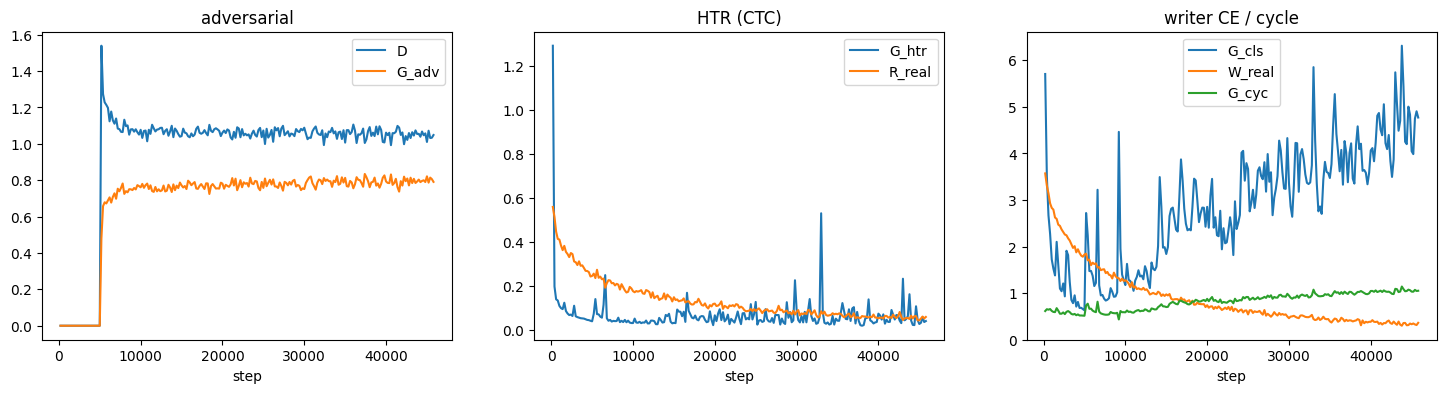

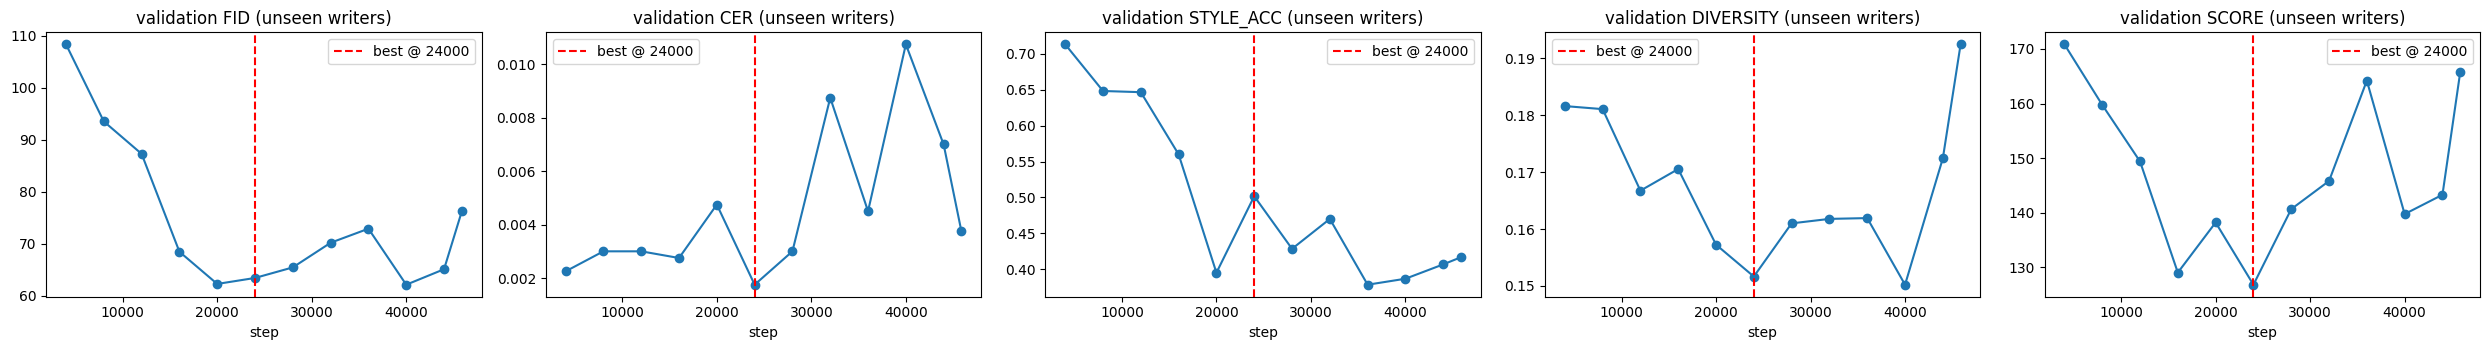

best model: 24000 {'cer': 0.0018, 'wer': 0.007, 'diversity': 0.1517, 'fid': 63.3878, 'style_acc': 0.5017, 'style_top5': 0.745, 'step': 24000, 'score': 126.7859}


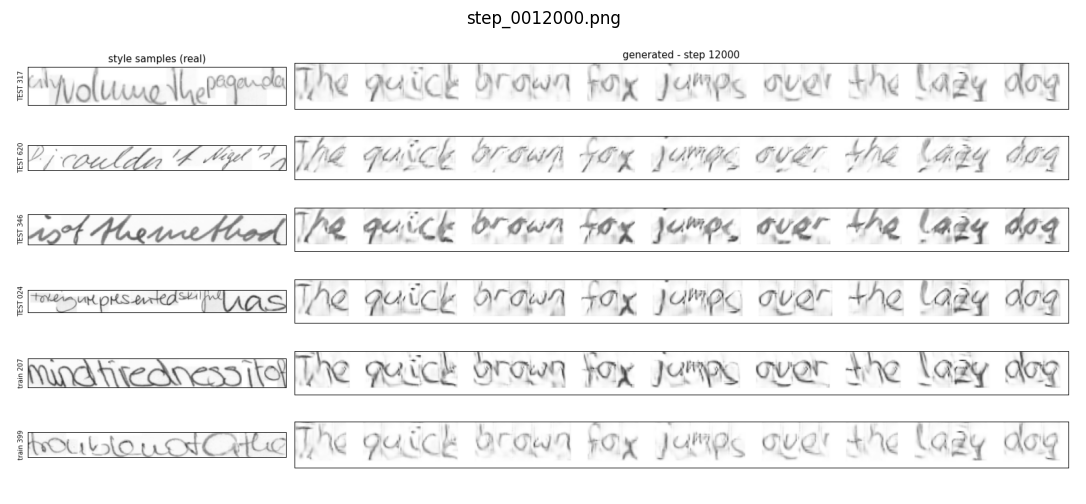

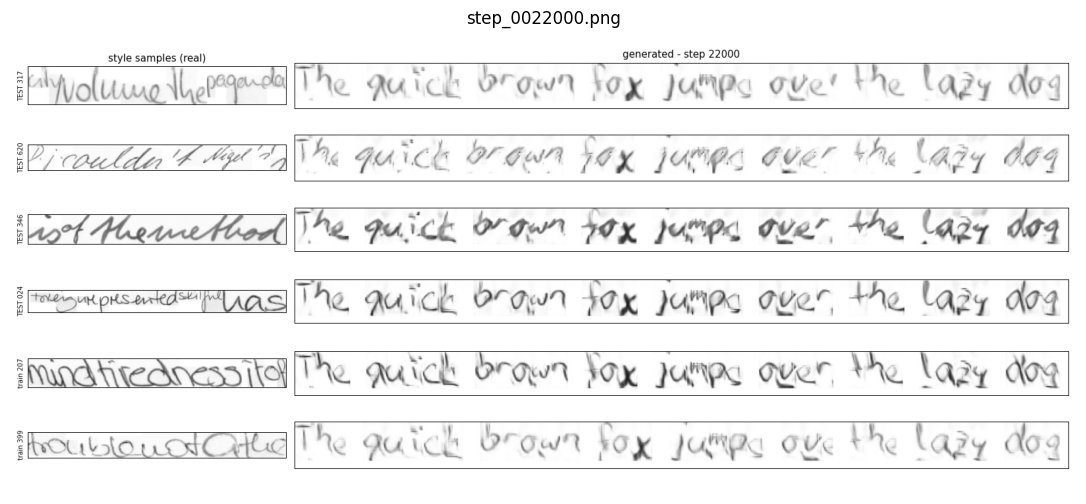

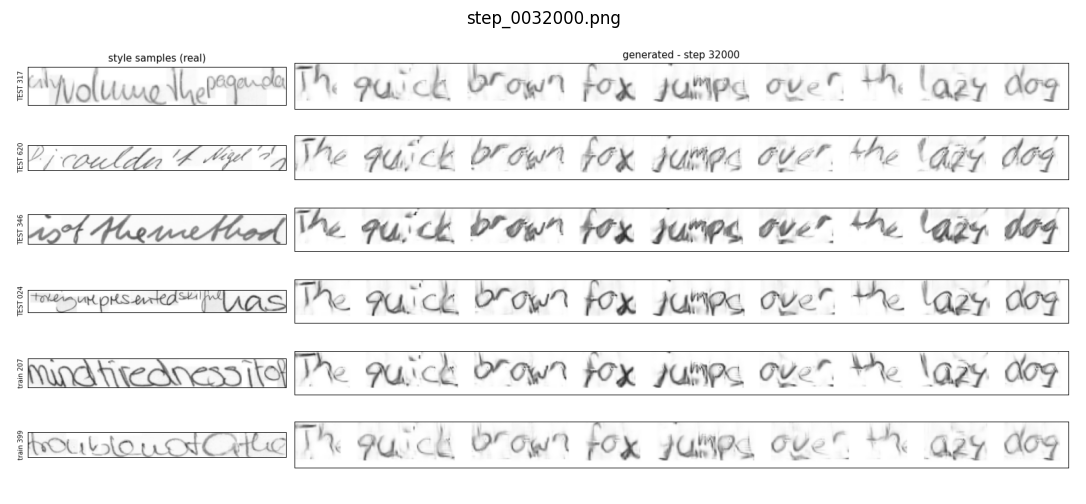

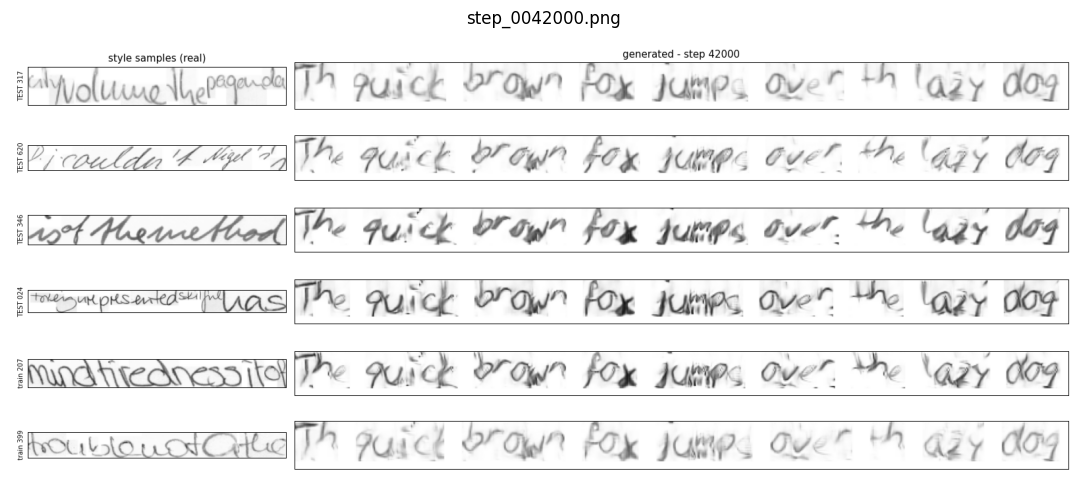

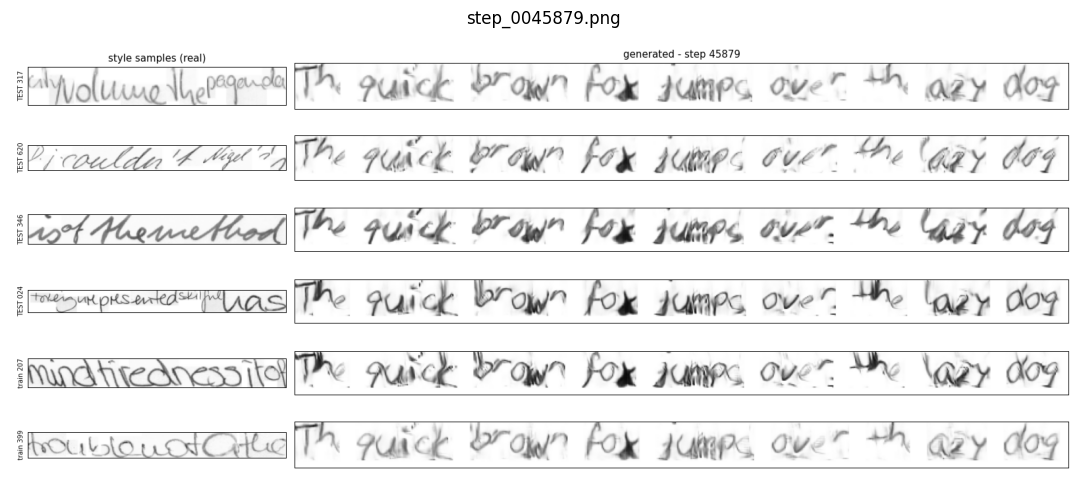

In [14]:
if STATE['history']:
    h = STATE['history']; steps = [r['step'] for r in h]
    fig, axs = plt.subplots(1, 3, figsize=(18, 4))
    for k in ('D', 'G_adv'): axs[0].plot(steps, [r[k] for r in h], label=k)
    for k in ('G_htr', 'R_real'): axs[1].plot(steps, [r[k] for r in h], label=k)
    for k in ('G_cls', 'W_real', 'G_cyc'): axs[2].plot(steps, [r[k] for r in h], label=k)
    for a, t in zip(axs, ('adversarial', 'HTR (CTC)', 'writer CE / cycle')): a.set_title(t); a.legend(); a.set_xlabel('step')
    plt.savefig(os.path.join(EVAL_DIR, 'training_losses.png'), dpi=90); plt.show()

if STATE['val_history']:
    vh = STATE['val_history']; vs = [r['step'] for r in vh]
    keys = [k for k in ('fid', 'cer', 'style_acc', 'diversity', 'score') if k in vh[0]]
    fig, axs = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.6), squeeze=False)
    for a, k in zip(axs[0], keys):
        a.plot(vs, [r[k] for r in vh], 'o-'); a.set_title(f'validation {k.upper()} (unseen writers)'); a.set_xlabel('step')
        a.axvline(STATE['best_step'], color='r', ls='--', label=f"best @ {STATE['best_step']}"); a.legend()
    plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, 'validation_curves.png'), dpi=90); plt.show()
    print('best model:', STATE['best_step'], {k: round(v, 4) for k, v in STATE['best_metrics'].items()})

sheets = sorted(glob.glob(os.path.join(SAMPLE_DIR, 'step_*.png')))
for p in sheets[:: max(1, len(sheets) // 4)][-4:] + sheets[-1:]:
    plt.figure(figsize=(18, 6)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(os.path.basename(p)); plt.show()

## 10. Full evaluation of the **best** model
1. Load `best_G.pt` (best validation score).
2. **Paired generation** (HWT/VATr protocol): for each real target word, the model writes the *same text* using 15 *other* words of the *same writer* as style. Two splits: **unseen** writers (test set, never seen in training) and **seen** writers (held-out words of training writers).
3. Content metrics (CER, WER, word accuracy, char P/R/F1, char confusion matrix) — with R's scores on the real words as reference.
4. Image-quality metrics: **FID, KID, GS** (generated vs real).
5. Style metrics: writer-ID accuracy / precision / recall / F1 / κ / MCC / top-5 + confusion matrix (seen writers), unseen-writer retrieval + confusion matrix.
6. Everything is printed as one table and saved to `/kaggle/working/evaluation/` (`metrics.csv`, `metrics.json`, plots).

Loaded BEST generator from step 24000 | validation: cer=0.0018, wer=0.0070, diversity=0.1517, fid=63.3878, style_acc=0.5017, style_top5=0.7450, step=24000.0000, score=126.7859
unseen: 5000 paired samples from 207 writers
seen  : 3275 paired samples from 424 writers
[unseen] generated CER=0.0055 WER=0.0218 word-acc=0.9784 | real CER=0.0790 WER=0.2214
[seen] generated CER=0.0034 WER=0.0131 word-acc=0.9869 | real CER=0.0717 WER=0.2009


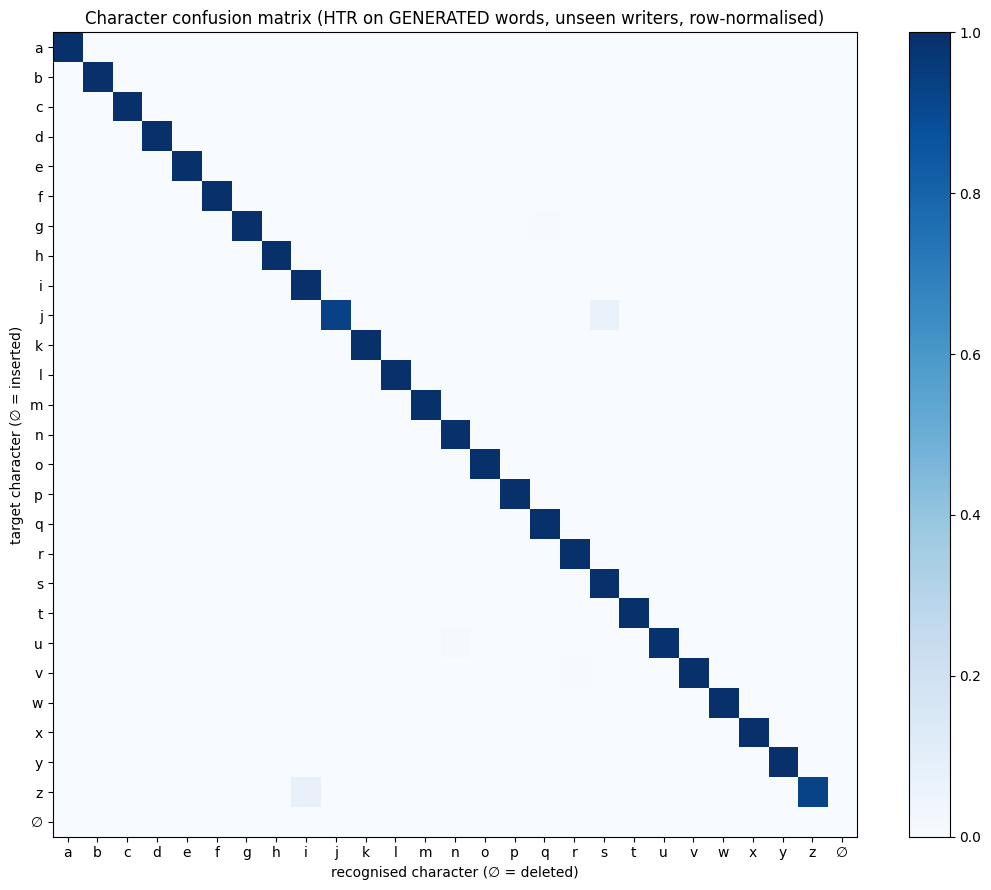

per-character precision / recall / F1 on generated words (unseen writers), 25 most frequent characters:
   precision  recall     f1  support
e      1.000   1.000  1.000   2525.0
t      0.999   1.000  0.999   1733.0
a      0.999   1.000  1.000   1532.0
o      0.997   0.999  0.998   1454.0
n      0.994   1.000  0.997   1317.0
i      0.998   1.000  0.999   1256.0
r      0.999   1.000  1.000   1224.0
s      0.997   0.999  0.998   1164.0
h      1.000   0.998  0.999   1132.0
d      1.000   1.000  1.000    818.0
l      1.000   1.000  1.000    807.0
u      0.998   0.991  0.995    577.0
c      1.000   1.000  1.000    556.0
m      1.000   0.998  0.999    488.0
f      0.989   1.000  0.995    457.0
w      1.000   1.000  1.000    410.0
p      1.000   1.000  1.000    363.0
y      1.000   1.000  1.000    356.0
g      1.000   0.994  0.997    350.0
b      1.000   1.000  1.000    303.0
.      0.960   1.000  0.980    263.0
,      0.887   1.000  0.940    243.0
v      1.000   0.995  0.997    184.0
k      0

In [15]:
_ck = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False) if os.path.exists(BEST_PATH) else None
if _ck is not None and _ck.get('version') == CKPT_VERSION:
    G_EMA.load_state_dict(_ck['G'])
    print(f"Loaded BEST generator from step {_ck['step']} | validation: " + ', '.join(f'{k}={v:.4f}' for k, v in _ck['metrics'].items()))
    del _ck
else:
    print('best_G.pt not found -> evaluating the final weights')
G_EMA.eval()

t_eval = time.time()
EVAL = {'unseen': generate_paired(G_EMA, sample_targets(test_idx, CFG.final_eval_n, seed=11), seed=11),
        'seen':   generate_paired(G_EMA, sample_targets(val_idx,  CFG.final_eval_n, seed=12), seed=12)}
for k, v in EVAL.items(): print(f'{k:6s}: {len(v["texts"])} paired samples from {len(set(v["writers"]))} writers')
RESULTS = defaultdict(dict)     # RESULTS[column][metric]

# ------------------------------------------------ 1. content: CER / WER / char P-R-F1
for split, out in EVAL.items():
    out['pred_fake'], out['pred_real'] = recognize(out['fake']), recognize(out['real'])
    mf, out['per_char'], out['pairs_fake'] = text_metrics(out['pred_fake'], out['texts'])
    mr, _, _ = text_metrics(out['pred_real'], out['texts'])
    RESULTS[f'{split} | generated'].update(mf); RESULTS[f'{split} | real (reference)'].update(mr)
    print(f"[{split}] generated CER={mf['CER']:.4f} WER={mf['WER']:.4f} word-acc={mf['word_accuracy']:.4f} | real CER={mr['CER']:.4f} WER={mr['WER']:.4f}")
plot_char_confusion(EVAL['unseen']['pairs_fake'], 'Character confusion matrix (HTR on GENERATED words, unseen writers, row-normalised)', 'char_confusion_unseen.png')
pc = pd.DataFrame(EVAL['unseen']['per_char']).T.sort_values('support', ascending=False)
print('per-character precision / recall / F1 on generated words (unseen writers), 25 most frequent characters:')
print(pc.head(25).round(3).to_string())
pc.to_csv(os.path.join(EVAL_DIR, 'per_character_metrics_unseen.csv'))

In [16]:
# ------------------------------------------------ 2. image quality: FID / KID / GS
if INCEPTION.ok:
    for split, out in EVAL.items():
        fr, ff = INCEPTION(out['real']), INCEPTION(out['fake'])
        kid_m, kid_s = kid_score(fr, ff)
        RESULTS[f'{split} | generated'].update(FID=fid_score(fr, ff), KID=kid_m, KID_std=kid_s)
        t0 = time.time(); gs = geometry_score(fr, ff)
        if gs is not None: RESULTS[f'{split} | generated']['GS'] = gs
        print(f"[{split}] FID={RESULTS[f'{split} | generated']['FID']:.3f}  KID={kid_m:.5f}±{kid_s:.5f}  GS={gs}  ({time.time()-t0:.0f}s for GS)")
    # reference: FID between the real 'unseen' and real 'seen' sets (= what two real sets of different writers score)
    RESULTS['unseen | real (reference)']['FID (real unseen vs real seen)'] = fid_score(INCEPTION(EVAL['unseen']['real']), INCEPTION(EVAL['seen']['real']))
else:
    print('FID / KID / GS skipped (Inception weights not available - turn Internet ON).')

[unseen] FID=51.079  KID=0.02462±0.00106  GS=0.009354341412502173  (15s for GS)
[seen] FID=53.342  KID=0.02462±0.00095  GS=0.004512707674472812  (15s for GS)


writer identification on GENERATED words (seen writers): {'accuracy': 0.5087, 'balanced_accuracy': 0.4575, 'precision_macro': 0.4841, 'recall_macro': 0.447, 'f1_macro': 0.4115, 'precision_weighted': 0.6406, 'recall_weighted': 0.5087, 'f1_weighted': 0.5211, 'cohen_kappa': 0.5056, 'mcc': 0.5062, 'top5_accuracy': 0.7325}
writer identification on REAL words      (seen writers): {'accuracy': 0.7218, 'balanced_accuracy': 0.6436, 'precision_macro': 0.6143, 'recall_macro': 0.6244, 'f1_macro': 0.5945, 'precision_weighted': 0.7655, 'recall_weighted': 0.7218, 'f1_weighted': 0.7277, 'cohen_kappa': 0.72, 'mcc': 0.7201, 'top5_accuracy': 0.8733}


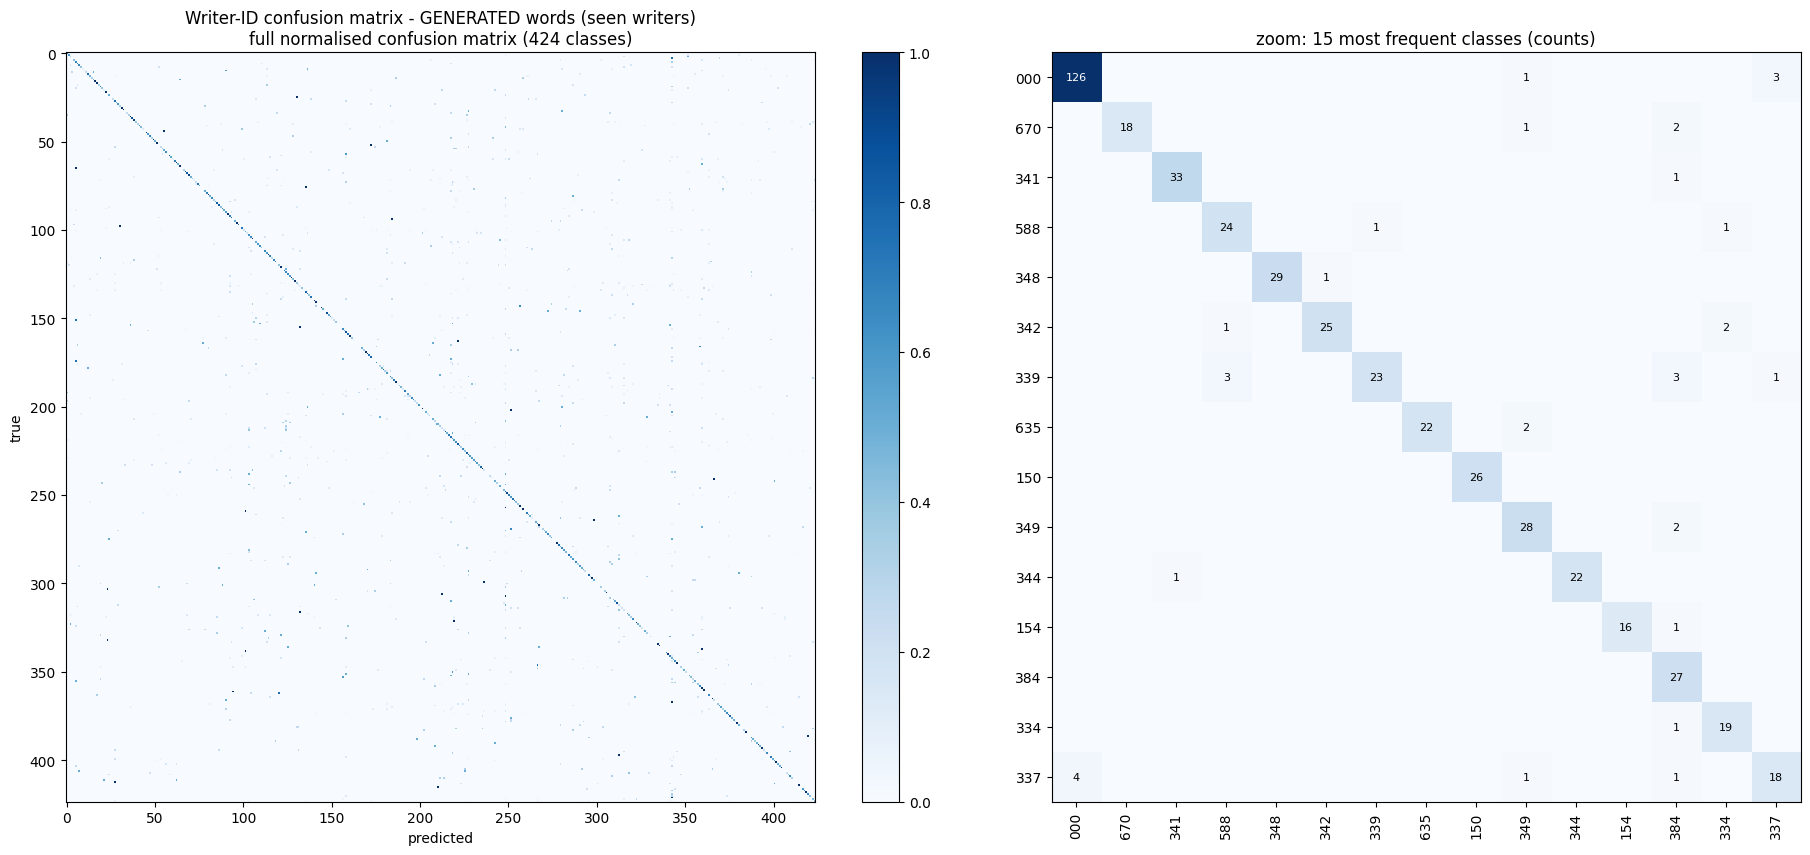

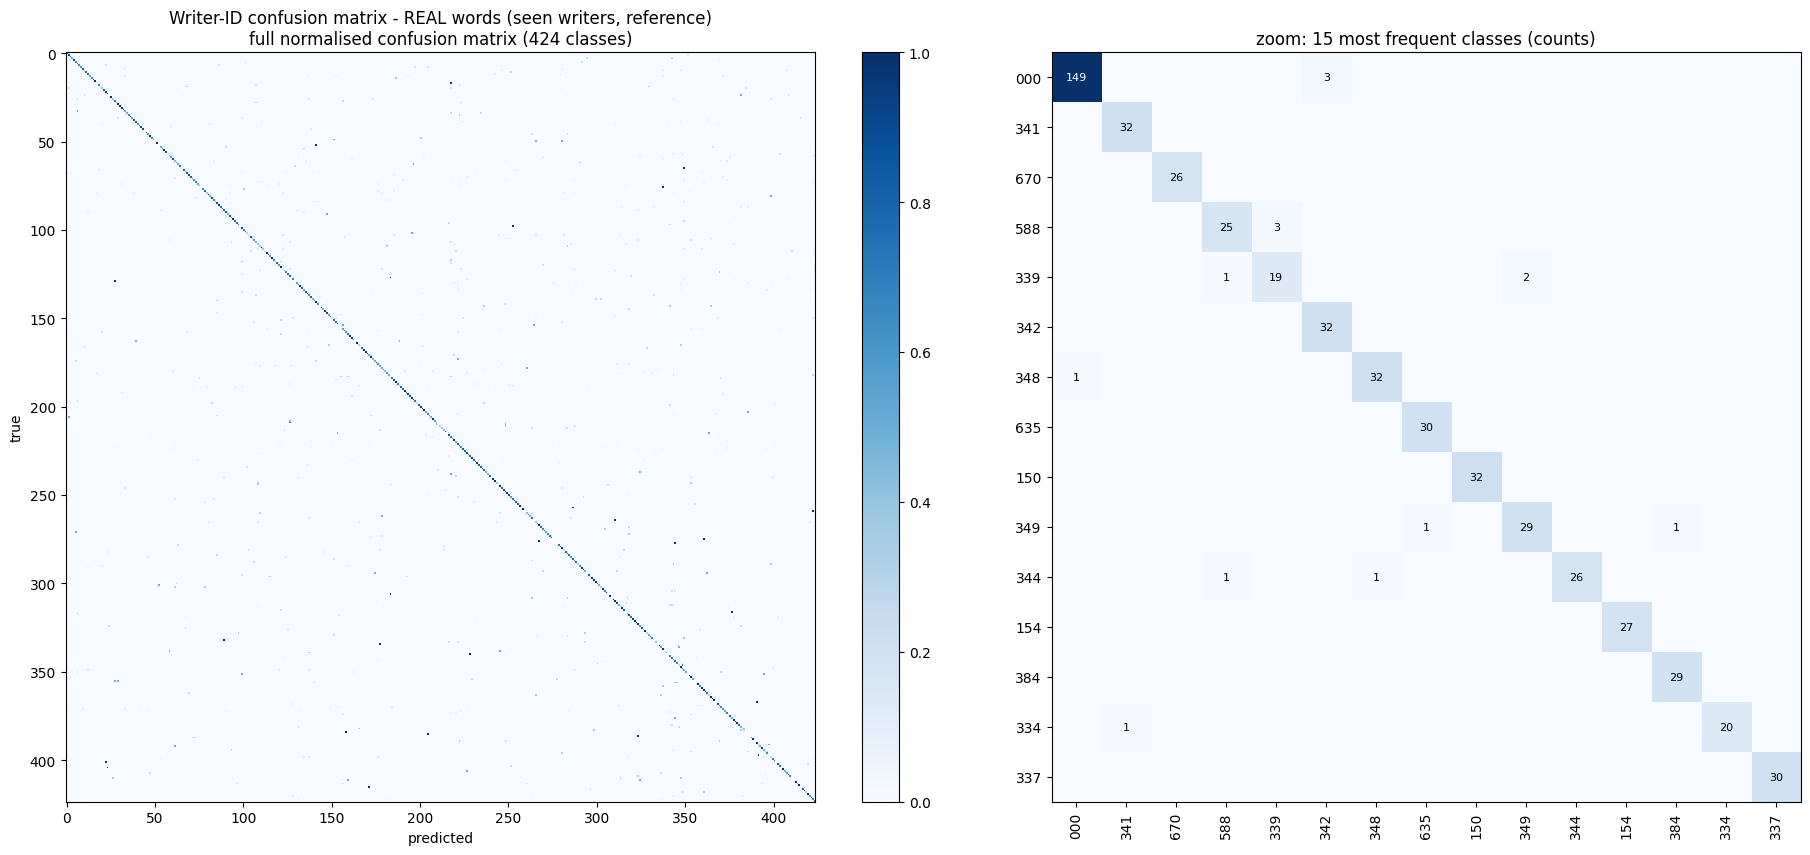

In [17]:
# ------------------------------------------------ 3. style, seen writers: writer identification by W
names = {i: w for w, i in W2I.items()}
out = EVAL['seen']
y_true = np.array([W2I[w] for w in out['writers']])
pf, _ = writer_predict(out['fake']); pr, _ = writer_predict(out['real'])
m_fake = classification_metrics(y_true, pf.argmax(1), pf, N_WRITERS); m_real = classification_metrics(y_true, pr.argmax(1), pr, N_WRITERS)
RESULTS['seen | generated'].update({f'writerID_{k}': v for k, v in m_fake.items()})
RESULTS['seen | real (reference)'].update({f'writerID_{k}': v for k, v in m_real.items()})
print('writer identification on GENERATED words (seen writers):', {k: round(v, 4) for k, v in m_fake.items()})
print('writer identification on REAL words      (seen writers):', {k: round(v, 4) for k, v in m_real.items()})
plot_confusion(y_true, pf.argmax(1), names, 'Writer-ID confusion matrix - GENERATED words (seen writers)', 'writer_confusion_seen_generated.png')
plot_confusion(y_true, pr.argmax(1), names, 'Writer-ID confusion matrix - REAL words (seen writers, reference)', 'writer_confusion_seen_real.png')

unseen-writer retrieval among 204 writers (chance = 0.0049)
  GENERATED sets: {'accuracy': 0.7108, 'balanced_accuracy': 0.7108, 'precision_macro': 0.7164, 'recall_macro': 0.7108, 'f1_macro': 0.6794, 'precision_weighted': 0.7164, 'recall_weighted': 0.7108, 'f1_weighted': 0.6794, 'cohen_kappa': 0.7094, 'mcc': 0.7101}
  REAL sets     : {'accuracy': 1.0, 'balanced_accuracy': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'f1_macro': 1.0, 'precision_weighted': 1.0, 'recall_weighted': 1.0, 'f1_weighted': 1.0, 'cohen_kappa': 1.0, 'mcc': 1.0}


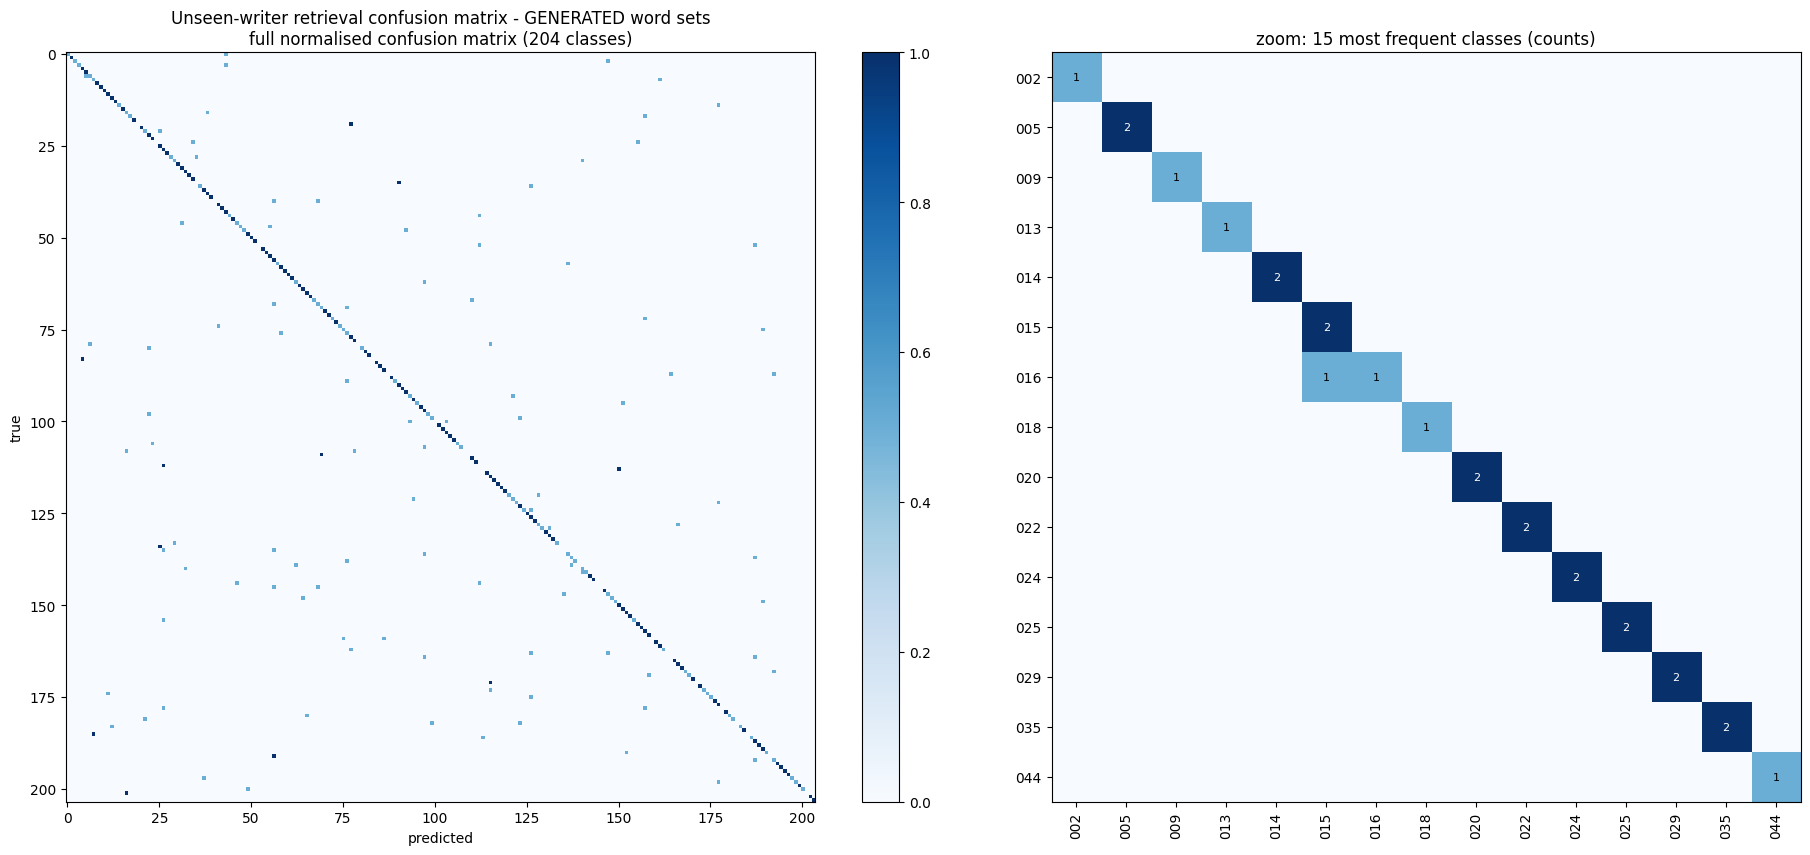

In [18]:
# ------------------------------------------------ 4. style, UNSEEN writers: retrieval with W features
@torch.no_grad()
def set_embedding(imgs):
    _, f = writer_predict(imgs); e = f.mean(0); return e / max(1e-8, np.linalg.norm(e))

@torch.no_grad()
def writer_retrieval(gen, trials=2, seed=21):
    # A = 15 words -> style input, B = 15 other words -> reference embedding, C = up to 15 more words -> texts to generate
    rng = random.Random(seed); torch.manual_seed(seed); P = CFG.num_style
    ws = [w for w in TEST_WRITERS if len(BY_WRITER_TEST[w]) >= 2 * P + 3]
    y_true, y_gen, y_real = [], [], []
    for _ in range(trials):
        refs, gq, rq = [], [], []
        for w in ws:
            pool = BY_WRITER_TEST[w][:]; rng.shuffle(pool)
            A, B, C = pool[:P], pool[P:2 * P], pool[2 * P:3 * P]
            refs.append(set_embedding([real_img(i) for i in B]))
            gq.append(set_embedding(generate_words(gen, make_style_tensor(A), [RECS[i]['text'] for i in C])))
            rq.append(set_embedding([real_img(i) for i in C]))
        refs = np.stack(refs)
        y_true += list(range(len(ws))); y_gen += list((np.stack(gq) @ refs.T).argmax(1)); y_real += list((np.stack(rq) @ refs.T).argmax(1))
    torch.seed()
    return np.array(y_true), np.array(y_gen), np.array(y_real), ws

yt, yg, yr, ret_ws = writer_retrieval(G_EMA)
if len(ret_ws) >= 2:
    m_g, m_r = classification_metrics(yt, yg), classification_metrics(yt, yr)
    RESULTS['unseen | generated'].update({f'retrieval_{k}': v for k, v in m_g.items()})
    RESULTS['unseen | real (reference)'].update({f'retrieval_{k}': v for k, v in m_r.items()})
    print(f'unseen-writer retrieval among {len(ret_ws)} writers (chance = {1/len(ret_ws):.4f})')
    print('  GENERATED sets:', {k: round(v, 4) for k, v in m_g.items()})
    print('  REAL sets     :', {k: round(v, 4) for k, v in m_r.items()})
    plot_confusion(yt, yg, dict(enumerate(ret_ws)), 'Unseen-writer retrieval confusion matrix - GENERATED word sets', 'writer_retrieval_unseen_generated.png')
else:
    print('not enough test writers with >= 33 words for the retrieval test')

In [19]:
# ------------------------------------------------ 5. summary table
REPORT = pd.DataFrame(RESULTS)
cols = [c for c in ('unseen | generated', 'unseen | real (reference)', 'seen | generated', 'seen | real (reference)') if c in REPORT.columns]
REPORT = REPORT[cols]
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 200)
print('=' * 110); print(f"FINAL METRICS - best model (step {STATE['best_step']}), evaluated in {time.time()-t_eval:.0f}s"); print('=' * 110)
_show = REPORT.round(4).astype(object).where(REPORT.notna(), '—')
_show.insert(0, 'better', ['±' if k == 'KID_std' else ('↓ lower' if any(x in k for x in ('CER', 'WER', 'FID', 'KID', 'GS')) else '↑ higher') for k in REPORT.index])
print(_show.to_string())
REPORT.to_csv(os.path.join(EVAL_DIR, 'metrics.csv'))
with open(os.path.join(EVAL_DIR, 'metrics.json'), 'w') as f:
    json.dump(dict(best_step=STATE['best_step'], best_validation=STATE['best_metrics'], total_steps=STATE['step'],
                   metrics={c: {k: (None if (isinstance(v, float) and not math.isfinite(v)) else v) for k, v in REPORT[c].dropna().items()} for c in cols}),
              f, indent=2, default=float)
print('\nsaved ->', os.path.join(EVAL_DIR, 'metrics.csv'), 'and metrics.json')

FINAL METRICS - best model (step 24000), evaluated in 220s
                                  better unseen | generated unseen | real (reference) seen | generated seen | real (reference)
CER                              ↓ lower             0.0055                     0.079           0.0034                  0.0717
WER                              ↓ lower             0.0218                    0.2214           0.0131                  0.2009
word_accuracy                   ↑ higher             0.9784                    0.7786           0.9869                  0.7994
char_precision_macro            ↑ higher             0.8753                    0.8448           0.8624                  0.8365
char_recall_macro               ↑ higher             0.8462                    0.7834           0.8671                  0.7628
char_f1_macro                   ↑ higher             0.8495                    0.8001           0.8627                    0.79
char_precision_micro            ↑ higher            

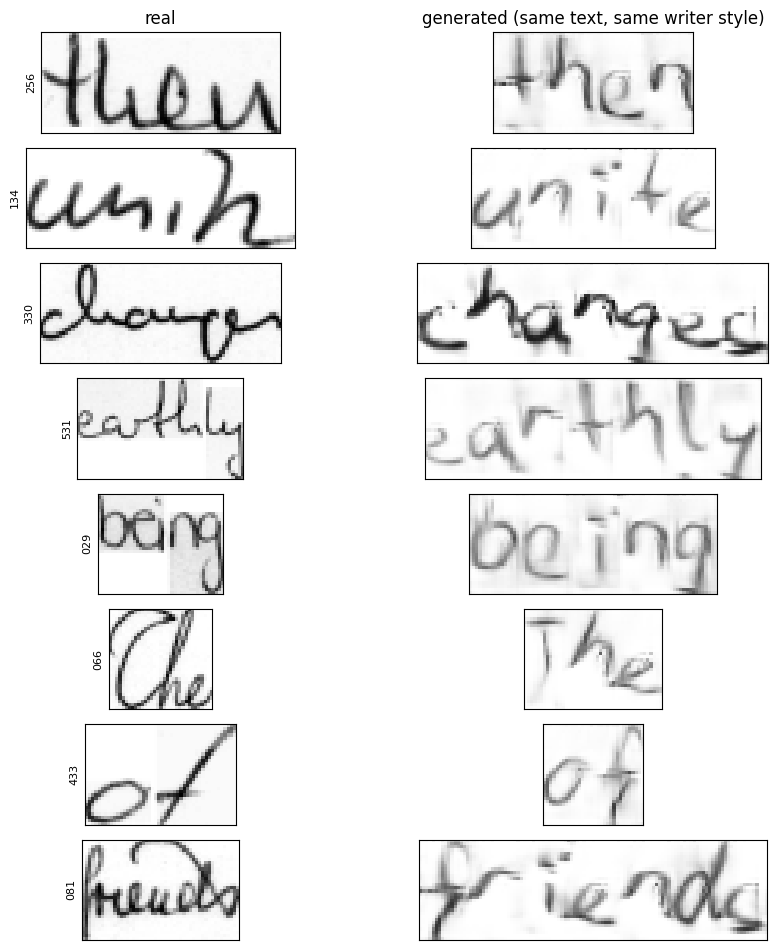

In [20]:
# real vs generated, same word, same writer (unseen writers)
rng = random.Random(7)
_ws = rng.sample([w for w in TEST_WRITERS if BY_WRITER_TEST[w]], min(8, len(TEST_WRITERS)))
fig, axs = plt.subplots(len(_ws), 2, figsize=(10, 1.2 * len(_ws)), squeeze=False)
for row, w in enumerate(_ws):
    st, _ = _style_for(w, rng)
    i = rng.choice(BY_WRITER_TEST[w])
    gen_img = generate_words(G_EMA, st, [RECS[i]['text']])[0]
    axs[row, 0].imshow(RECS[i]['img'], cmap='gray'); axs[row, 0].set_ylabel(w, fontsize=8)
    axs[row, 1].imshow(trim_word(gen_img), cmap='gray', vmin=-1, vmax=1)
    for a in axs[row]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_title('real'); axs[0, 1].set_title('generated (same text, same writer style)')
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, 'real_vs_generated.png'), dpi=100); plt.show()

## 11. Generate YOUR text in ANY handwriting style (uses the best model)
Three ways to give a style:
1. **IAM writer id** (e.g. one of the unseen test writers),
2. **a folder of word images** (one word per image, e.g. crops of your handwriting),
3. **a photo/scan of a handwritten page** — it is automatically binarised, segmented into words and used as the 15 style samples.

To use your own handwriting on Kaggle: write ~20 words on white paper with a dark pen, photograph it flat in good light, upload it as a Kaggle dataset (or to the notebook's *Input*), and set `STYLE_SOURCE` to its path.

In [21]:
def normalize_page(gray):
    # remove uneven illumination and stretch contrast -> white paper, dark ink (like IAM)
    k = max(31, (min(gray.shape) // 20) | 1)
    bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    norm = cv2.divide(gray, bg, scale=255)
    lo = np.percentile(norm, 1)
    return np.clip((norm.astype(np.float32) - lo) / max(1, 255 - lo) * 255, 0, 255).astype(np.uint8)

def segment_words(gray, debug=False):
    # photo of a handwritten page -> list of word crops (uint8, white background), in reading order
    if max(gray.shape) > 2500:
        s = 2500 / max(gray.shape); gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    norm = normalize_page(gray)
    _, bw = cv2.threshold(cv2.GaussianBlur(norm, (3, 3), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(bw, 8)
    hs = stats[1:, cv2.CC_STAT_HEIGHT][stats[1:, cv2.CC_STAT_AREA] > 15]
    if len(hs) == 0: return []
    xh = float(np.median(hs))                                    # ~ x-height of the writing
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (max(3, int(xh * 0.5)), max(1, int(xh * 0.35))))
    merged = cv2.dilate(bw, kernel)
    cnts, _ = cv2.findContours(merged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = [cv2.boundingRect(c) for c in cnts]
    boxes = [b for b in boxes if b[3] > 0.6 * xh and b[2] > 0.5 * xh and b[3] < 8 * xh]
    boxes.sort(key=lambda b: b[1] + b[3] / 2)
    lines, cur = [], []
    for b in boxes:                                              # group boxes into text lines
        if cur and abs((b[1] + b[3] / 2) - np.mean([c[1] + c[3] / 2 for c in cur])) > 1.2 * xh:
            lines.append(cur); cur = []
        cur.append(b)
    if cur: lines.append(cur)
    crops = []
    for ln in lines:
        for x, y, w, h in sorted(ln, key=lambda b: b[0]):
            m = bw[y:y + h, x:x + w] > 0
            ys, xs = np.where(m)
            if len(ys) == 0: continue
            y0, y1, x0, x1 = y + ys.min(), y + ys.max() + 1, x + xs.min(), x + xs.max() + 1
            p = 3
            crops.append(norm[max(0, y0 - p):y1 + p, max(0, x0 - p):x1 + p])
    if debug:
        vis = cv2.cvtColor(norm, cv2.COLOR_GRAY2BGR)
        for ln in lines:
            for x, y, w, h in ln: cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
        plt.figure(figsize=(12, 8)); plt.imshow(vis); plt.title(f'{len(crops)} words found'); plt.axis('off'); plt.show()
    return crops

def crops_to_style(crops, rng=None):
    rng = rng or random.Random(0)
    crops = [c for c in crops if c.size > 0]
    assert crops, 'no handwriting found'
    crops = sorted(crops, key=lambda c: -c.shape[1])[:max(CFG.num_style, len(crops) // 2)]   # prefer longer words
    pick = rng.sample(crops, CFG.num_style) if len(crops) >= CFG.num_style else rng.choices(crops, k=CFG.num_style)
    imgs = []
    for c in pick:
        h, w = c.shape
        r = cv2.resize(c, (max(4, int(round(w * CFG.img_h / h))), CFG.img_h), interpolation=cv2.INTER_AREA)
        imgs.append(u8_to_t(style_format(r)))
    return torch.stack(imgs)[:, None], pick

def get_style(source, show=True):
    # source: 'iam:<writer_id>' | path to a folder of word images | path to a page image
    if source.startswith('iam:'):
        w = source[4:]
        assert w in BY_WRITER or w in BY_WRITER_TEST, f'unknown writer {w}'
        st, idx = _style_for(w, random.Random(0))
        crops = [RECS[i]['img'] for i in idx]
    elif os.path.isdir(source):
        files = sorted(f for f in glob.glob(os.path.join(source, '*')) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')))
        crops = [normalize_page(cv2.imread(f, cv2.IMREAD_GRAYSCALE)) for f in files]
        st, crops = crops_to_style(crops)
    else:
        gray = cv2.imread(source, cv2.IMREAD_GRAYSCALE)
        assert gray is not None, f'cannot read {source}'
        st, crops = crops_to_style(segment_words(gray, debug=show))
    if show:
        fig, axs = plt.subplots(1, min(8, len(crops)), figsize=(16, 1.2))
        for a, c in zip(np.atleast_1d(axs), crops): a.imshow(c, cmap='gray'); a.axis('off')
        plt.suptitle('style samples used', y=1.1); plt.show()
    return st

def handwrite(text, source, max_width=1000, seed=0, save_as=None, show=True):
    st = get_style(source, show=show)
    page = write_text(G_EMA, st, text, max_width=max_width, seed=seed)
    img = Image.fromarray(((np.clip(page, -1, 1) + 1) * 127.5).astype(np.uint8))
    img = img.resize((img.width * 2, img.height * 2), Image.BICUBIC)        # 2x for nicer viewing
    if save_as: img.save(save_as); print('saved ->', save_as)
    if show:
        plt.figure(figsize=(min(20, img.width / 80), max(2, img.height / 80))); plt.imshow(img, cmap='gray'); plt.axis('off'); plt.show()
    return img

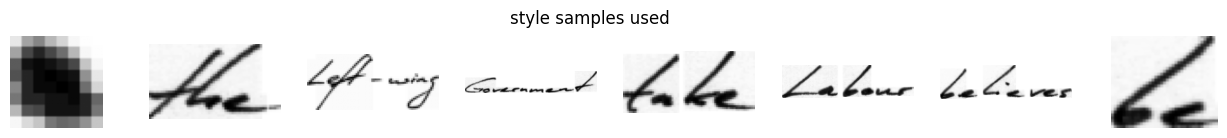

saved -> /kaggle/working/my_handwriting.png


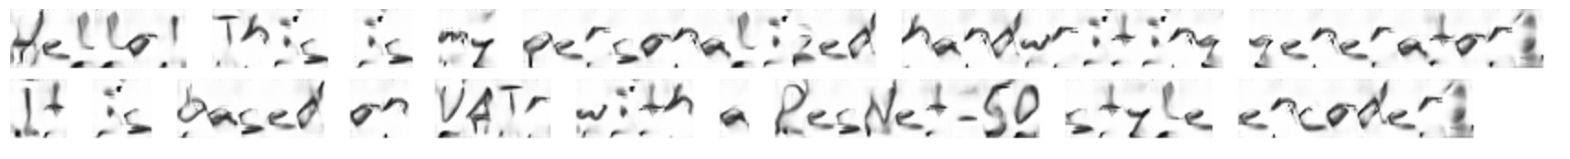

writer 118


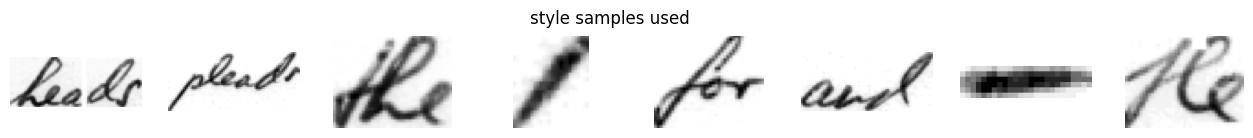

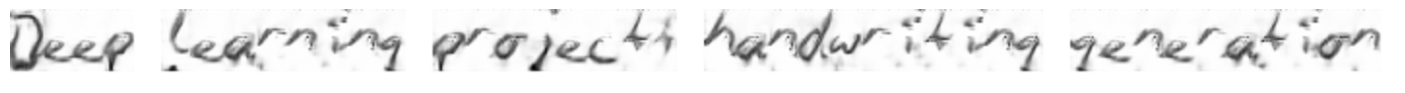

writer 464


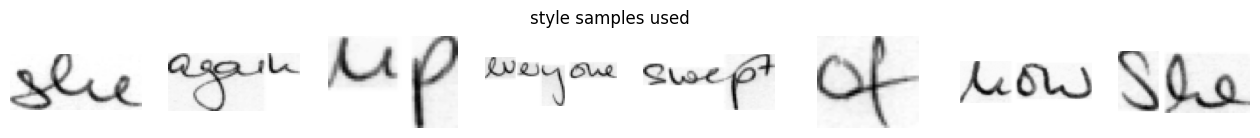

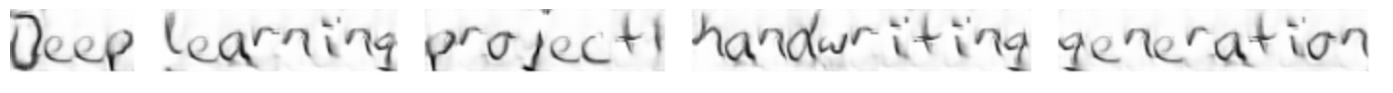

writer 663


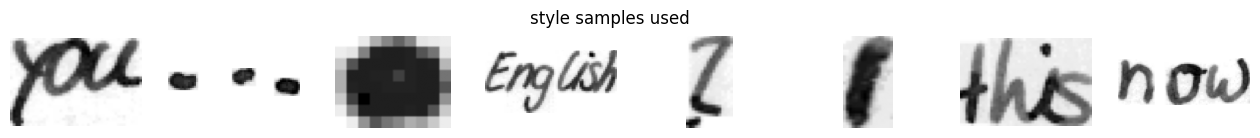

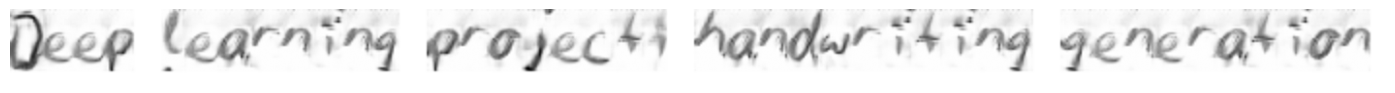

In [22]:
# ====================== TRY IT ======================
TEXT = '''Hello! This is my personalized handwriting generator.
It is based on VATr with a ResNet-50 style encoder.'''

STYLE_SOURCE = 'iam:' + TEST_WRITERS[0]      # an unseen IAM writer
# STYLE_SOURCE = '/kaggle/input/my-handwriting/page.jpg'      # <- a photo of YOUR handwriting
# STYLE_SOURCE = '/kaggle/input/my-handwriting/words/'        # <- a folder of word crops

out = handwrite(TEXT, STYLE_SOURCE, save_as=os.path.join(CFG.work_dir, 'my_handwriting.png'))

# same text, several different writers
for w in random.Random(1).sample(TEST_WRITERS, min(3, len(TEST_WRITERS))):
    print('writer', w); handwrite('Deep learning project: handwriting generation', 'iam:' + w, show=True)

## 12. Export the trained generator
`vatr_resnet50_generator.pt` (the **best** EMA generator + charset + config + its metrics) is all you need for inference later, e.g. in a local app.

In [23]:
export_path = os.path.join(CFG.work_dir, 'vatr_resnet50_generator.pt')
torch.save(dict(G=G_EMA.state_dict(), charset=CHARSET, cfg={k: v for k, v in vars(CFG).items() if not k.startswith('_')},
                best_step=STATE['best_step'], best_validation=STATE['best_metrics'],
                final_metrics={c: REPORT[c].dropna().to_dict() for c in REPORT.columns} if 'REPORT' in globals() else None), export_path)
print('exported', export_path, f'({os.path.getsize(export_path)/1e6:.0f} MB)')

exported /kaggle/working/vatr_resnet50_generator.pt (130 MB)


## 13. (Optional) Interactive web demo with Gradio
Set `RUN_GRADIO = True` (needs Internet on). It prints a public `*.gradio.live` link: type text, upload a photo of your handwriting (or type an IAM writer id) and get the generated image.

In [24]:
RUN_GRADIO = False
if RUN_GRADIO:
    try:
        import gradio as gr
    except ImportError:
        os.system('pip -q install gradio'); import gradio as gr
    def _demo(text, photo, writer_id, seed):
        if photo is not None:
            path = os.path.join(CFG.work_dir, '_upload.png'); Image.fromarray(photo).convert('L').save(path); src = path
        else:
            src = 'iam:' + (writer_id.strip() or TEST_WRITERS[0])
        return handwrite(text, src, seed=int(seed), show=False)
    gr.Interface(_demo,
                 [gr.Textbox(lines=4, value='Hello world, this is my handwriting!', label='Text'),
                  gr.Image(label='Photo of handwriting (optional)'),
                  gr.Textbox(value=TEST_WRITERS[0], label='...or IAM writer id'),
                  gr.Number(value=0, label='seed')],
                 gr.Image(label='Generated handwriting'), title='Personalized Handwriting Generator (VATr + ResNet-50)').launch(share=True)

## 14. Notes — complete project summary

### What this notebook does end-to-end (one *Save & Run All*)
| Step | Cell(s) | Output |
|---|---|---|
| Find + parse IAM (`words.txt`, `forms.txt`, word PNGs) | §1 | ~96k words, 657 writers |
| Cache images (32 px high) | §1 | `cache/iam_h32.pkl` |
| Writer split: ~68 % train writers (styles learned), ~32 % **unseen** test writers | §2 | |
| Visual archetypes (GNU Unifont 16×16 glyphs) | §3 | |
| Stage 1: pre-train ResNet-50 style backbone, HTR recognizer R, writer classifier W | §7 | val CER / WER / writer accuracy |
| Stage 2: VATr GAN training (L_adv + L_HTR + L_class + L_cycle), EMA generator, validation every `eval_every` steps | §8 | `checkpoints/last.pt`, **`checkpoints/best_G.pt`**, `samples/*.png` |
| Training curves + validation curves | §9 | `evaluation/training_losses.png`, `validation_curves.png` |
| Full evaluation of the best model (all metrics, confusion matrices) | §10 | `evaluation/metrics.csv`, `metrics.json`, plots |
| Generation: any text × any style (IAM writer, word folder, photo of your page) | §11 | `my_handwriting.png` |
| Export | §12 | `vatr_resnet50_generator.pt` |

### How the "best model" is chosen
* Every `CFG.eval_every` steps the EMA generator writes 1 000 test words of **unseen** writers; we compute **FID** (vs. the real words) and **CER** (HTR on the generated words).
* Validation also measures **style accuracy**: the writer classifier W must recognise the intended writer in words generated for 600 held-out words of training writers.
* Score = FID × (1 + CER) × (1 + 2·(1 − style accuracy)) (lower is better) — it rewards realistic, legible **and personalised** handwriting. Without Inception weights FID is replaced by 100·CER.
* Whenever the score improves, `best_G.pt` is overwritten. The final evaluation, the generation cells and the export **all use `best_G.pt`**. The best score survives across sessions (stored in `last.pt`).

### Reading the metrics
* **CER / WER (generated)** close to the **real-reference** column ⇒ content is as legible as real handwriting.
* **FID / KID / GS**: lower is better; compare with "FID (real unseen vs real seen)", the distance between two *real* sets, as a lower-bound reference. (The VATr paper reports FID ≈ 17.8 on IAM at 64 px height with a different protocol, so numbers are not directly comparable.)
* **Writer-ID metrics on generated words (seen writers)**: how often an independent classifier, trained only on real handwriting, attributes the generated words to the intended writer. Compare with the real-reference column (upper bound).
* **Unseen-writer retrieval**: same idea for writers never seen in training (chance level is printed).
* The **confusion matrices** show which characters are confused (e.g. `a↔o`, `n↔u`, `l↔i`) and which writers are mixed up.

### Run 2 → this version: personalisation fixes
Run 2 (v5) wrote **legible** text (CER 0.03, word accuracy 88 %, FID 66.7, KID 0.032, GS 0.007) but **ignored the style**: writer-ID on generated words 0.6 % (real 69 %), unseen-writer retrieval 1.2 % (chance 0.5 %); all writers got the same handwriting. The log showed why: the cycle loss fell to ≈ 0 after step 24 k (the style encoder mapped every writer to the same vector) and the generated words were classified worse than chance (G_cls 9.6). Fixes:
* **writer-classification loss on the style vectors** (`S_cls` in the log) keeps the style encoder writer-aware;
* the writer-pre-trained **ResNet-50 backbone is frozen** in stage 2;
* a **global style path** (mean style vector → every character token) next to the cross-attention;
* **style accuracy is part of every validation and of the best-model score**.

What to look for: `S_cls` should fall well below log(#writers) ≈ 6; validation `style_acc` should rise clearly above chance (≈ 0.2 %); the rows of the sample sheet should look **different from each other**.

### Training stability (lessons from run 1)
Run 1 (old notebook version) **collapsed**: every character came out as the same blob, for every word and every writer (CER ≈ 1.0, FID ≈ 204, writer metrics at chance) while the evaluators themselves were fine (real CER 0.11, real writer-ID 71 %, real-vs-real FID 5). Causes and fixes in this version:
* the auxiliary gradients were wildly unbalanced (writer-classifier gradient ≈ 200× the HTR gradient; adversarial also stronger) so the text was ignored → **gradient balancing of all losses** (HWT/VATr) + **content warm-up** without D;
* D could tell real from fake by aspect ratio alone and its loss went to 0 → **real words resized to 16 px per character**, **D lr halved**;
* noise std 1.0 had the same magnitude as the content features → **0.2**;
* a **diversity** score is now part of every validation (≈ 0 means collapse) and old checkpoints are ignored (version tag).

**What to look for in the log**: during the warm-up `G_htr` must go down (towards ≈ 1 or lower); after it, `D` should stay roughly between 0.5 and 1.8 (not → 0), `a_htr` / `a_cls` are the balancing factors, and validation `cer` should fall below ~0.5 within the first session. Samples in `samples/` should show readable, different words.

### Getting the best results
1. **Train longer** — GAN handwriting models keep improving for a long time. Run 2–3 sessions (each ≈ 11 h): attach the previous notebook output as input and run again; training, the best-model tracking and the metrics continue automatically.
2. Use a **P100 / T4** with Internet ON (ImageNet weights for ResNet-50 & Inception, GNU Unifont).
3. If you see `CUDA out of memory` messages, lower `CFG.batch_size` (8 → 6) or `CFG.n_fake` (4 → 2).
4. Optional knobs: `CFG.noise_std` (variability of the strokes), loss weights `CFG.w_*`, `CFG.eval_every`.
5. For your own style: ~20+ words, dark pen on white paper, photographed flat in good light; check the red boxes of the segmentation preview.

### Files in `/kaggle/working`
`checkpoints/last.pt` (full training state) · `checkpoints/best_G.pt` (best generator) · `samples/` (progress sheets) · `evaluation/` (metrics.csv, metrics.json, per_character_metrics_unseen.csv, confusion matrices, curves, real-vs-generated) · `my_handwriting.png` · `vatr_resnet50_generator.pt` · `cache/`